# OCT Eye Disease: Feature Visualization & Interpretability (EfficientNet-B1)

Adapts the baseline CNN visualization pipeline for the **EfficientNet-B1** model
trained in Stage 1 / Stage 2.

Visualizations:
- **Grad-CAM** – Class activation maps (last Conv2D inside the EfficientNet backbone)
- **Feature Maps** – Representative conv filter activations across backbone depth
- **t-SNE** – Learned 1792-D GAP embedding projected to 2-D
- **Advanced Metrics** – Balanced accuracy, MCC, Cohen's kappa, AUC (OVR)


## Setup and Imports

In [1]:
!pip install kaggle==1.6.17
import os
os.makedirs("/root/.kaggle", exist_ok=True)
!mv kaggle.json /root/.kaggle/
!chmod 600 /root/.kaggle/kaggle.json
!kaggle datasets download -d anirudhcv/labeled-optical-coherence-tomography-oct
!unzip /content/labeled-optical-coherence-tomography-oct.zip -d /content/

Streaming output truncated to the last 5000 lines.
  inflating: /content/Dataset - train+val+test/val/NORMAL/NORMAL-5822041-15.jpeg  
  inflating: /content/Dataset - train+val+test/val/NORMAL/NORMAL-5822041-16.jpeg  
  inflating: /content/Dataset - train+val+test/val/NORMAL/NORMAL-5822041-18.jpeg  
  inflating: /content/Dataset - train+val+test/val/NORMAL/NORMAL-5822041-2.jpeg  
  inflating: /content/Dataset - train+val+test/val/NORMAL/NORMAL-5822041-8.jpeg  
  inflating: /content/Dataset - train+val+test/val/NORMAL/NORMAL-582215-6.jpeg  
  inflating: /content/Dataset - train+val+test/val/NORMAL/NORMAL-582215-7.jpeg  
  inflating: /content/Dataset - train+val+test/val/NORMAL/NORMAL-582215-8.jpeg  
  inflating: /content/Dataset - train+val+test/val/NORMAL/NORMAL-5823731-1.jpeg  
  inflating: /content/Dataset - train+val+test/val/NORMAL/NORMAL-5823731-5.jpeg  
  inflating: /content/Dataset - train+val+test/val/NORMAL/NORMAL-5824080-5.jpeg  
  inflating: /content/Dataset - train+val+test/

In [2]:
# Mount Google Drive for persistent storage across sessions
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import os
import json
import zipfile
import tempfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras import mixed_precision
from tensorflow.keras.applications import EfficientNetB1
from tensorflow.keras.layers import (
    Input, Concatenate, GlobalAveragePooling2D,
    Dense, Dropout, BatchNormalization,
)
from sklearn.metrics import (
    classification_report, confusion_matrix,
    balanced_accuracy_score, matthews_corrcoef, cohen_kappa_score,
    roc_auc_score, roc_curve, auc, precision_recall_curve,
)
from sklearn.preprocessing import label_binarize

mixed_precision.set_global_policy('mixed_float16')
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 8)

# - Paths -
OUTPUT_DIR_EFFICIENTNET = Path("/content/drive/MyDrive/oct_outputs_efficientnet_b1")
OUTPUT_DIR = Path("/content/drive/MyDrive/oct_outputs_featureViz_efficientnet_b1")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# - Load Stage 1 metadata -
with open(OUTPUT_DIR_EFFICIENTNET / "stage1_meta.json") as f:
    meta = json.load(f)

IMG_SIZE     = tuple(meta["img_size"])   # (224, 224)
BATCH_SIZE   = 8
COLOR_MODE   = meta["color_mode"]        # "grayscale"
NUM_CHANNELS = meta["num_channels"]      # 1
SEED         = meta["seed"]              # 42
class_names  = meta["class_names"]
num_classes  = meta["num_classes"]
AUTOTUNE     = tf.data.AUTOTUNE

DATASET_ROOT = "/content/Dataset - train+val+test"
TRAIN_DIR = os.path.join(DATASET_ROOT, "train")
VAL_DIR   = os.path.join(DATASET_ROOT, "val")
TEST_DIR  = os.path.join(DATASET_ROOT, "test")

print(f"TensorFlow: {tf.__version__}")
print(f"Classes:    {class_names}")
print(f"IMG_SIZE:   {IMG_SIZE}  |  Channels: {NUM_CHANNELS}")
print(f"EfficientNet dir: {OUTPUT_DIR_EFFICIENTNET}")
print(f"Viz output  dir:  {OUTPUT_DIR}")


TensorFlow: 2.20.0
Classes:    ['CNV', 'DME', 'DRUSEN', 'NORMAL']
IMG_SIZE:   (224, 224)  |  Channels: 1
EfficientNet dir: /content/drive/MyDrive/oct_outputs_efficientnet_b1
Viz output  dir:  /content/drive/MyDrive/oct_outputs_featureViz_efficientnet_b1


## Load Data and Model

In [4]:
# - 1. Datasets -
def load_dataset(split_dir, shuffle):
    ds = tf.keras.utils.image_dataset_from_directory(
        split_dir,
        labels="inferred",
        label_mode="categorical",
        color_mode=COLOR_MODE,
        batch_size=BATCH_SIZE,
        image_size=IMG_SIZE,
        shuffle=shuffle,
        seed=SEED if shuffle else None,
        interpolation="bilinear",
    )
    names = ds.class_names
    return ds.prefetch(AUTOTUNE), names

training_set,   class_names = load_dataset(TRAIN_DIR, shuffle=True)
validation_set, _           = load_dataset(VAL_DIR,   shuffle=False)
test_set,       _           = load_dataset(TEST_DIR,  shuffle=False)
num_classes = len(class_names)
print("Datasets loaded.  Classes:", class_names)

# - 2. Rebuild EfficientNet-B1 architecture (must match Stage 1 / Stage 2) -
tf.keras.backend.clear_session()

inputs = Input(shape=IMG_SIZE + (NUM_CHANNELS,), name="oct_input")
x = Concatenate(axis=-1)([inputs, inputs, inputs])   # grayscale -> RGB
x = tf.keras.applications.efficientnet.preprocess_input(x)

backbone = EfficientNetB1(
    input_shape=IMG_SIZE + (3,),
    include_top=False,
    weights="imagenet",
)
backbone.trainable = False

x = backbone(x, training=False)
x = GlobalAveragePooling2D()(x)
x = Dense(512, activation="relu", name="fc1")(x)
x = BatchNormalization()(x)
x = Dropout(0.5)(x)
x = Dense(256, activation="relu", name="fc2")(x)
x = BatchNormalization()(x)
x = Dropout(0.3)(x)
outputs = Dense(num_classes, activation="softmax", name="predictions", dtype="float32")(x)

model = tf.keras.Model(inputs=inputs, outputs=outputs, name="efficientnet_b1_oct")

# - 3. Load weights: prefer final model, fall back to stage2, then stage1 -
final_path  = OUTPUT_DIR_EFFICIENTNET / "efficientnet_b1_final.keras"
stage2_path = OUTPUT_DIR_EFFICIENTNET / "best_efficientnet_stage2.keras"
stage1_path = OUTPUT_DIR_EFFICIENTNET / "best_efficientnet_stage1.keras"
if final_path.exists():
    keras_path = final_path
elif stage2_path.exists():
    keras_path = stage2_path
else:
    keras_path = stage1_path
print(f"Loading weights from: {keras_path}")

with zipfile.ZipFile(str(keras_path), "r") as zf:
    with tempfile.TemporaryDirectory() as tmp:
        zf.extract("model.weights.h5", tmp)
        model.load_weights(os.path.join(tmp, "model.weights.h5"))

print(f"Model loaded  -  {model.count_params():,} parameters")
print(f"Input shape:  {model.input_shape}")


Found 76515 files belonging to 4 classes.
Found 21861 files belonging to 4 classes.
Found 10933 files belonging to 4 classes.
Datasets loaded.  Classes: ['CNV', 'DME', 'DRUSEN', 'NORMAL']
27018416/27018416 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Loading weights from: /content/drive/MyDrive/oct_outputs_efficientnet_b1/efficientnet_b1_final.keras
Model loaded  -  7,366,539 parameters
Input shape:  (None, 224, 224, 1)


## Grad-CAM: Class Activation Mapping

Visualize which regions of OCT images influence model predictions.

In [5]:
# ---------------------------------------------------------------------------
# Grad-CAM for EfficientNet-B1
#
# Keras 3 removed the `weights=` constructor argument from layers.
# Weights must be assigned via set_weights() AFTER the layer is built,
# which happens automatically when the layer is called for the first time
# inside a tf.keras.Model. We therefore build the model first (call it
# once to trigger building), then copy the weights.
# ---------------------------------------------------------------------------

def _get_backbone(model):
    for layer in model.layers:
        if "efficientnetb1" in layer.name.lower():
            return layer
    raise RuntimeError("EfficientNetB1 backbone not found in model.")


def _last_conv_name(backbone):
    name = None
    for layer in backbone.layers:
        if isinstance(layer, tf.keras.layers.Conv2D):
            name = layer.name
    if name is None:
        raise RuntimeError("No Conv2D found inside EfficientNet backbone.")
    return name


class GradCAM:
    """
    Grad-CAM for EfficientNet-B1.

    Builds a single end-to-end model with two outputs that share the same
    forward pass, so GradientTape gradients are never None.

    Compatible with Keras 3: weights are copied via set_weights() after
    the model is built (i.e. after the first call), NOT via the constructor.
    """

    def __init__(self, model):
        backbone          = _get_backbone(model)
        self.target_layer = _last_conv_name(backbone)
        print(f"Grad-CAM target layer (inside backbone): {self.target_layer}")

        # - Backbone sub-model with two outputs ---------------
        # backbone is a pre-built functional model, so .input/.output are valid
        conv_tensor = backbone.get_layer(self.target_layer).output
        backbone_dual = tf.keras.Model(
            inputs=backbone.input,
            outputs=[conv_tensor, backbone.output],
            name="backbone_dual",
        )

        # - Build the full pipeline with a standalone grayscale Input ----
        inp    = tf.keras.Input(shape=IMG_SIZE + (NUM_CHANNELS,), name="gc_in")
        x_rgb  = Concatenate(axis=-1)([inp, inp, inp])
        x_prep = tf.keras.layers.Lambda(
            tf.keras.applications.efficientnet.preprocess_input,
            name="gc_preprocess",
        )(x_rgb)

        conv_out, bb_out = backbone_dual(x_prep)

        gap = GlobalAveragePooling2D(name="gc_gap")(bb_out)

        # Define head layers WITHOUT weights= (Keras 3 does not support it)
        fc1_layer  = Dense(512, activation="relu",    name="gc_fc1")
        bn1_layer  = BatchNormalization(name="gc_bn1")
        dr1_layer  = Dropout(0.5,                     name="gc_dr1")
        fc2_layer  = Dense(256, activation="relu",    name="gc_fc2")
        bn2_layer  = BatchNormalization(name="gc_bn2")
        dr2_layer  = Dropout(0.3,                     name="gc_dr2")
        out_layer  = Dense(num_classes, activation="softmax",
                           dtype="float32",           name="gc_out")

        h = fc1_layer(gap)
        h = bn1_layer(h)
        h = dr1_layer(h)
        h = fc2_layer(h)
        h = bn2_layer(h)
        h = dr2_layer(h)
        preds = out_layer(h)

        self.grad_model = tf.keras.Model(
            inputs=inp,
            outputs=[conv_out, preds],
            name="gradcam_model",
        )

        # - Trigger a build pass so all layers are initialised -------─
        dummy = tf.zeros((1,) + IMG_SIZE + (NUM_CHANNELS,))
        self.grad_model(dummy, training=False)

        # - Copy weights from the trained model (now safe to call set_weights) ─
        self.grad_model.get_layer("gc_fc1").set_weights(
            model.get_layer("fc1").get_weights()
        )
        self.grad_model.get_layer("gc_fc2").set_weights(
            model.get_layer("fc2").get_weights()
        )
        self.grad_model.get_layer("gc_out").set_weights(
            model.get_layer("predictions").get_weights()
        )

        # BatchNorm layers - match by position (same order as in trained model)
        orig_bns = [l for l in model.layers
                    if isinstance(l, tf.keras.layers.BatchNormalization)]
        self.grad_model.get_layer("gc_bn1").set_weights(orig_bns[0].get_weights())
        self.grad_model.get_layer("gc_bn2").set_weights(orig_bns[1].get_weights())

        print("GradCAM model built and weights copied successfully.")

    def __call__(self, x, class_idx):
        """Return a (H, W) heatmap in [0, 1]."""
        x = tf.cast(tf.convert_to_tensor(x), tf.float32)

        with tf.GradientTape() as tape:
            tape.watch(x)
            conv_outputs, predictions = self.grad_model(x, training=False)
            conv_outputs = tf.cast(conv_outputs, tf.float32)
            predictions  = tf.cast(predictions,  tf.float32)
            loss = predictions[:, class_idx]

        grads = tape.gradient(loss, conv_outputs)
        if grads is None:
            raise RuntimeError(
                "Gradients are None - conv_outputs and predictions must share "
                "the same forward pass inside grad_model."
            )
        grads = tf.cast(grads, tf.float32)

        pooled_grads    = tf.reduce_mean(grads, axis=(0, 1, 2))      # (C,)
        conv_out_single = conv_outputs[0]                             # (H, W, C)
        heatmap = conv_out_single @ pooled_grads[..., tf.newaxis]     # (H, W, 1)
        heatmap = tf.squeeze(heatmap)

        heatmap     = tf.maximum(heatmap, 0.0)
        heatmap_max = tf.reduce_max(heatmap)
        if heatmap_max > 0:
            heatmap = heatmap / heatmap_max

        return heatmap.numpy()


grad_cam = GradCAM(model)
print(f"Grad-CAM initialised  -  target: {grad_cam.target_layer}")


Grad-CAM target layer (inside backbone): top_conv
GradCAM model built and weights copied successfully.
Grad-CAM initialised  -  target: top_conv


## Generate Grad-CAM Visualizations for Test Samples

Predictions generated for 80 test images.


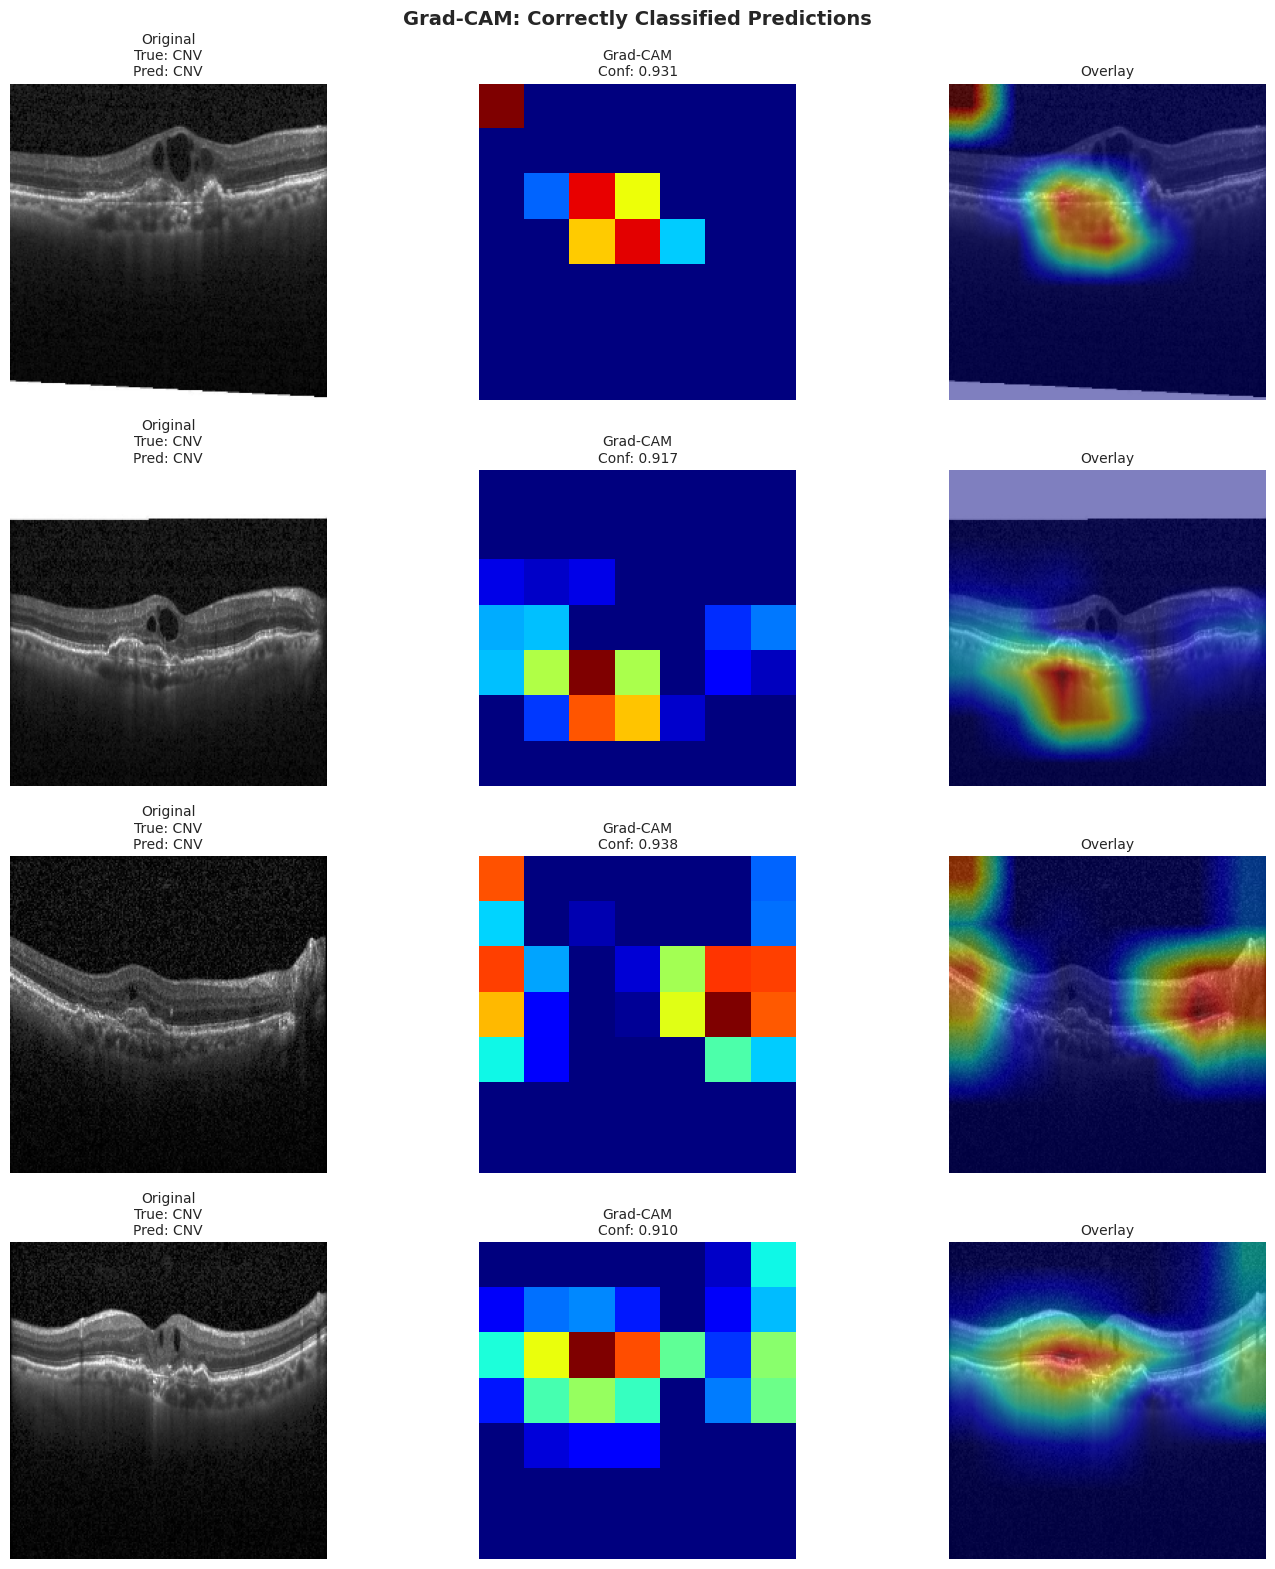

Grad-CAM visualizations saved.


In [6]:
def overlay_gradcam(image, heatmap, alpha=0.4):
    """Overlay Grad-CAM heatmap on a grayscale image."""
    img_display = (image - image.min()) / (image.max() - image.min() + 1e-8)
    # Resize heatmap to match IMG_SIZE
    heatmap_resized = tf.image.resize(
        heatmap[np.newaxis, :, :, np.newaxis], IMG_SIZE
    ).numpy()[0, :, :, 0]
    img_rgb = np.stack([img_display.squeeze()] * 3, axis=-1)  # (H, W, 3)
    # Jet colormap for heatmap
    heatmap_colored = plt.cm.jet(heatmap_resized)[:, :, :3]   # (H, W, 3)
    result = (1 - alpha) * img_rgb + alpha * heatmap_colored
    return np.clip(result, 0, 1)


# Collect a small batch of test images (10 batches × BATCH_SIZE)
test_images_list, test_labels_list = [], []
for images, labels in test_set.take(10):
    test_images_list.append(images.numpy())
    test_labels_list.append(labels.numpy())

test_images = np.concatenate(test_images_list, axis=0)
test_labels = np.concatenate(test_labels_list, axis=0)

y_pred_proba_small = model.predict(test_images, verbose=0)
y_pred_classes     = np.argmax(y_pred_proba_small, axis=1)
y_true_classes     = np.argmax(test_labels, axis=1)

print(f"Predictions generated for {len(test_images)} test images.")

correct_mask     = y_pred_classes == y_true_classes
correct_indices  = np.where(correct_mask)[0][:4]
incorrect_indices = np.where(~correct_mask)[0][:4]

# - Plot correctly classified samples -
fig, axes = plt.subplots(4, 3, figsize=(15, 16))
fig.suptitle("Grad-CAM: Correctly Classified Predictions", fontsize=14, fontweight="bold")

for row, idx in enumerate(correct_indices):
    image      = test_images[idx]
    true_class = class_names[y_true_classes[idx]]
    pred_class = class_names[y_pred_classes[idx]]
    confidence = y_pred_proba_small[idx, y_pred_classes[idx]]

    axes[row, 0].imshow(np.squeeze(image), cmap="gray")
    axes[row, 0].set_title(f"Original\nTrue: {true_class}\nPred: {pred_class}", fontsize=10)
    axes[row, 0].axis("off")

    heatmap = grad_cam(image[np.newaxis, ...], y_pred_classes[idx])
    axes[row, 1].imshow(heatmap, cmap="jet")
    axes[row, 1].set_title(f"Grad-CAM\nConf: {confidence:.3f}", fontsize=10)
    axes[row, 1].axis("off")

    overlay = overlay_gradcam(np.squeeze(image), heatmap, alpha=0.5)
    axes[row, 2].imshow(overlay)
    axes[row, 2].set_title("Overlay", fontsize=10)
    axes[row, 2].axis("off")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "gradcam_correct_predictions.png", dpi=300, bbox_inches="tight")
plt.show()

# - Plot misclassified samples -
if len(incorrect_indices) > 0:
    n_rows = min(4, len(incorrect_indices))
    fig, axes = plt.subplots(n_rows, 3, figsize=(15, 4 * n_rows))
    if n_rows == 1:
        axes = axes[np.newaxis, :]
    fig.suptitle("Grad-CAM: Misclassified Predictions", fontsize=14, fontweight="bold")

    for row, idx in enumerate(incorrect_indices[:n_rows]):
        image      = test_images[idx]
        true_class = class_names[y_true_classes[idx]]
        pred_class = class_names[y_pred_classes[idx]]
        confidence = y_pred_proba_small[idx, y_pred_classes[idx]]

        axes[row, 0].imshow(np.squeeze(image), cmap="gray")
        axes[row, 0].set_title(
            f"Original\nTrue: {true_class}\nPred: {pred_class} (ERROR)",
            fontsize=10, color="red", fontweight="bold"
        )
        axes[row, 0].axis("off")

        heatmap = grad_cam(image[np.newaxis, ...], y_pred_classes[idx])
        axes[row, 1].imshow(heatmap, cmap="jet")
        axes[row, 1].set_title(f"Grad-CAM\nConf: {confidence:.3f}", fontsize=10)
        axes[row, 1].axis("off")

        overlay = overlay_gradcam(np.squeeze(image), heatmap, alpha=0.5)
        axes[row, 2].imshow(overlay)
        axes[row, 2].set_title("Overlay", fontsize=10)
        axes[row, 2].axis("off")

    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "gradcam_incorrect_predictions.png", dpi=300, bbox_inches="tight")
    plt.show()

print("Grad-CAM visualizations saved.")

## Grad-CAM: Multi-Layer Activation Maps

Visualize Grad-CAM heatmaps across all (or up to 6 evenly-spaced) Conv2D layers inside the EfficientNet-B1 backbone — one row per layer — for both correctly and incorrectly classified samples.

> **Note:** Each `GradCAMLayer` instance builds its own `grad_model` pointing to a specific conv layer, using the same weight-copy approach as the single-layer `GradCAM` class above.

In [7]:
# ---------------------------------------------------------------------------
# GradCAMLayer: same architecture as GradCAM but targets any named conv layer
# inside the EfficientNet-B1 backbone instead of always using the last one.
# ---------------------------------------------------------------------------

class GradCAMLayer:
    """
    Grad-CAM for EfficientNet-B1 targeting a specific conv layer by name.

    Identical weight-copy approach to the GradCAM class; only the target
    conv tensor changes. Each instance builds its own grad_model.
    """

    def __init__(self, model, conv_layer_name):
        self.target_layer = conv_layer_name
        backbone = _get_backbone(model)

        # Backbone sub-model: chosen conv layer output + full backbone output
        conv_tensor   = backbone.get_layer(conv_layer_name).output
        backbone_dual = tf.keras.Model(
            inputs=backbone.input,
            outputs=[conv_tensor, backbone.output],
            name=f"backbone_dual_{conv_layer_name[-12:]}",
        )

        # Full pipeline with standalone grayscale Input
        inp    = tf.keras.Input(shape=IMG_SIZE + (NUM_CHANNELS,),
                                name=f"gc_in_{conv_layer_name[-12:]}")
        x_rgb  = Concatenate(axis=-1)([inp, inp, inp])
        x_prep = tf.keras.layers.Lambda(
            tf.keras.applications.efficientnet.preprocess_input,
            name=f"gc_prep_{conv_layer_name[-12:]}",
        )(x_rgb)

        conv_out, bb_out = backbone_dual(x_prep)
        gap = GlobalAveragePooling2D(name=f"gc_gap_{conv_layer_name[-12:]}")(bb_out)

        sfx = conv_layer_name[-10:]   # short suffix keeps layer names unique
        fc1_layer = Dense(512, activation="relu",  name=f"gc_fc1_{sfx}")
        bn1_layer = BatchNormalization(             name=f"gc_bn1_{sfx}")
        dr1_layer = Dropout(0.5,                   name=f"gc_dr1_{sfx}")
        fc2_layer = Dense(256, activation="relu",  name=f"gc_fc2_{sfx}")
        bn2_layer = BatchNormalization(             name=f"gc_bn2_{sfx}")
        dr2_layer = Dropout(0.3,                   name=f"gc_dr2_{sfx}")
        out_layer = Dense(num_classes, activation="softmax",
                          dtype="float32",         name=f"gc_out_{sfx}")

        h = fc1_layer(gap); h = bn1_layer(h); h = dr1_layer(h)
        h = fc2_layer(h);   h = bn2_layer(h); h = dr2_layer(h)
        preds = out_layer(h)

        self.grad_model = tf.keras.Model(
            inputs=inp,
            outputs=[conv_out, preds],
            name=f"gradcam_model_{conv_layer_name[-12:]}",
        )

        # Trigger build pass
        dummy = tf.zeros((1,) + IMG_SIZE + (NUM_CHANNELS,))
        self.grad_model(dummy, training=False)

        # Copy weights from trained model
        self.grad_model.get_layer(f"gc_fc1_{sfx}").set_weights(
            model.get_layer("fc1").get_weights())
        self.grad_model.get_layer(f"gc_fc2_{sfx}").set_weights(
            model.get_layer("fc2").get_weights())
        self.grad_model.get_layer(f"gc_out_{sfx}").set_weights(
            model.get_layer("predictions").get_weights())

        orig_bns = [l for l in model.layers
                    if isinstance(l, tf.keras.layers.BatchNormalization)]
        self.grad_model.get_layer(f"gc_bn1_{sfx}").set_weights(orig_bns[0].get_weights())
        self.grad_model.get_layer(f"gc_bn2_{sfx}").set_weights(orig_bns[1].get_weights())

    def __call__(self, x, class_idx):
        """Return a (H, W) heatmap in [0, 1]."""
        x = tf.cast(tf.convert_to_tensor(x), tf.float32)

        with tf.GradientTape() as tape:
            tape.watch(x)
            conv_outputs, predictions = self.grad_model(x, training=False)
            conv_outputs = tf.cast(conv_outputs, tf.float32)
            predictions  = tf.cast(predictions,  tf.float32)
            loss = predictions[:, class_idx]

        grads = tape.gradient(loss, conv_outputs)
        if grads is None:
            raise RuntimeError("Gradients are None.")
        grads = tf.cast(grads, tf.float32)

        pooled_grads    = tf.reduce_mean(grads, axis=(0, 1, 2))
        conv_out_single = conv_outputs[0]
        heatmap = conv_out_single @ pooled_grads[..., tf.newaxis]
        heatmap = tf.squeeze(heatmap)

        heatmap     = tf.maximum(heatmap, 0.0)
        heatmap_max = tf.reduce_max(heatmap)
        if heatmap_max > 0:
            heatmap = heatmap / heatmap_max

        return heatmap.numpy()


# ── Select conv layers (exclude SE bottlenecks, cap at 6 evenly-spaced) ──
backbone = _get_backbone(model)

all_conv_names = [
    l.name for l in backbone.layers
    if isinstance(l, tf.keras.layers.Conv2D)
    and "se_reduce" not in l.name
    and "se_expand" not in l.name
]
print(f"Conv2D layers available (excl. SE): {len(all_conv_names)}")

MAX_LAYERS = 6
if len(all_conv_names) > MAX_LAYERS:
    indices = np.linspace(0, len(all_conv_names) - 1, MAX_LAYERS, dtype=int)
    selected_layer_names = [all_conv_names[i] for i in indices]
    print(f"Using {MAX_LAYERS} evenly-spaced layers:")
else:
    selected_layer_names = all_conv_names
    print(f"Using all {len(selected_layer_names)} layers:")

for n in selected_layer_names:
    print(f"  {n}")

print("\nBuilding GradCAMLayer instances (this may take a moment)...")
grad_cams_all = [GradCAMLayer(model, name) for name in selected_layer_names]
print(f"\n{len(grad_cams_all)} GradCAMLayer instances ready.")


# ── Helper: one figure per sample, one row per layer ──────────────────────
def plot_multilayer_gradcam_efficientnet(image, true_class, pred_class, confidence,
                                         layer_names, grad_cams, class_idx,
                                         is_correct=True, sample_num=1):
    """Plot Original | Grad-CAM heatmap | Overlay for each conv layer (one row each)."""
    n_layers = len(layer_names)
    fig, axes = plt.subplots(n_layers, 3, figsize=(15, 4 * n_layers))
    if n_layers == 1:
        axes = axes[np.newaxis, :]

    status_str  = "\u2713 Correct"  if is_correct else "\u2717 Incorrect"
    title_color = "darkgreen"        if is_correct else "red"
    fig.suptitle(
        f"Multi-Layer Grad-CAM (EfficientNet-B1)  |  {status_str}  |  Sample {sample_num}\n"
        f"True: {true_class}   Pred: {pred_class}   Conf: {confidence:.3f}",
        fontsize=13, fontweight="bold", color=title_color,
    )

    img_display = (image - image.min()) / (image.max() - image.min() + 1e-8)

    for row, (layer_name, gcam) in enumerate(zip(layer_names, grad_cams)):
        heatmap = gcam(image[np.newaxis, ...], class_idx)

        axes[row, 0].imshow(np.squeeze(img_display), cmap="gray")
        axes[row, 0].set_title(f"Original\n[{layer_name}]", fontsize=8)
        axes[row, 0].axis("off")

        axes[row, 1].imshow(heatmap, cmap="jet")
        axes[row, 1].set_title(f"Grad-CAM Heatmap\n[{layer_name}]", fontsize=8)
        axes[row, 1].axis("off")

        overlay = overlay_gradcam(np.squeeze(image), heatmap, alpha=0.5)
        axes[row, 2].imshow(overlay)
        axes[row, 2].set_title(f"Overlay\n[{layer_name}]", fontsize=8)
        axes[row, 2].axis("off")

    plt.tight_layout()
    return fig


# ── Correctly classified samples ──────────────────────────────────────────
print("\nGenerating multi-layer Grad-CAM for correctly classified samples...")
for sample_i, idx in enumerate(correct_indices):
    image      = test_images[idx]
    true_class = class_names[y_true_classes[idx]]
    pred_class = class_names[y_pred_classes[idx]]
    confidence = y_pred_proba_small[idx, y_pred_classes[idx]]

    fig = plot_multilayer_gradcam_efficientnet(
        image, true_class, pred_class, confidence,
        selected_layer_names, grad_cams_all,
        class_idx=y_pred_classes[idx],
        is_correct=True, sample_num=sample_i + 1,
    )
    save_path = OUTPUT_DIR / f"gradcam_multilayer_correct_sample{sample_i + 1}.png"
    fig.savefig(save_path, dpi=200, bbox_inches="tight")
    plt.show()
    print(f"  Saved: {save_path}")


# ── Misclassified samples ─────────────────────────────────────────────────
if len(incorrect_indices) > 0:
    print("\nGenerating multi-layer Grad-CAM for misclassified samples...")
    for sample_i, idx in enumerate(incorrect_indices):
        image      = test_images[idx]
        true_class = class_names[y_true_classes[idx]]
        pred_class = class_names[y_pred_classes[idx]]
        confidence = y_pred_proba_small[idx, y_pred_classes[idx]]

        fig = plot_multilayer_gradcam_efficientnet(
            image, true_class, pred_class, confidence,
            selected_layer_names, grad_cams_all,
            class_idx=y_pred_classes[idx],
            is_correct=False, sample_num=sample_i + 1,
        )
        save_path = OUTPUT_DIR / f"gradcam_multilayer_incorrect_sample{sample_i + 1}.png"
        fig.savefig(save_path, dpi=200, bbox_inches="tight")
        plt.show()
        print(f"  Saved: {save_path}")
else:
    print("No misclassified samples found in this batch.")

print("\nMulti-layer Grad-CAM visualizations complete.")


Output hidden; open in https://colab.research.google.com to view.

## Feature Map Visualization: How Filters Learn Across Epochs

This section requires retraining the model with checkpoints at epochs 1, 5, 10, 15, 20 to capture filter evolution.

In [8]:
from tensorflow.keras.callbacks import Callback

class EpochCheckpointCallback(Callback):
    """Save model at specific epochs for feature visualization."""
    def __init__(self, checkpoint_epochs, output_dir):
        super().__init__()
        self.checkpoint_epochs = checkpoint_epochs
        self.output_dir = Path(output_dir)
        self.output_dir.mkdir(exist_ok=True)

    def on_epoch_end(self, epoch, logs=None):
        if (epoch + 1) in self.checkpoint_epochs:
            checkpoint_path = self.output_dir / f"model_epoch_{epoch+1}.keras"
            self.model.save(str(checkpoint_path))
            print(f"\nCheckpoint saved: {checkpoint_path}")

checkpoint_epochs = [1, 5, 10, 15, 20, 25, 30]
print(f"Feature map evolution requires checkpoints at epochs: {checkpoint_epochs}")
print("Add EpochCheckpointCallback to training callbacks to generate them.")

Feature map evolution requires checkpoints at epochs: [1, 5, 10, 15, 20, 25, 30]
Add EpochCheckpointCallback to training callbacks to generate them.


In [9]:
# ---------------------------------------------------------------------------
# Feature Map Visualization for EfficientNet-B1
#
# Two issues fixed:
#   1. SE reduce/expand layers (block*_se_reduce, block*_se_expand) produce
#      near-zero activations on grayscale OCT images - they are skipped when
#      selecting representative layers.
#   2. Dead filters (std < 1e-4) are shown with a grey "inactive" tile and a
#      count label instead of a misleading solid-colour square.
# ---------------------------------------------------------------------------

def visualize_feature_maps_efficientnet(model, input_image, max_layers=6):
    """
    Extract feature maps from representative Conv2D layers in the backbone.

    Skips SE bottleneck layers (se_reduce / se_expand) which are routinely
    silent for grayscale inputs. Selects `max_layers` evenly-spaced layers
    from the remaining pool.

    Returns (features, conv_layer_objects).
    """
    backbone = _get_backbone(model)

    # Collect Conv2D layers, excluding SE bottlenecks
    all_conv = [
        l for l in backbone.layers
        if isinstance(l, tf.keras.layers.Conv2D)
        and "se_reduce" not in l.name
        and "se_expand" not in l.name
    ]
    print(f"Total Conv2D layers in backbone : {len([l for l in backbone.layers if isinstance(l, tf.keras.layers.Conv2D)])}")
    print(f"After excluding SE bottlenecks  : {len(all_conv)}")

    # Evenly-spaced selection across network depth
    if len(all_conv) <= max_layers:
        selected = all_conv
    else:
        idx      = np.linspace(0, len(all_conv) - 1, max_layers, dtype=int)
        selected = [all_conv[i] for i in idx]

    print(f"Visualising {len(selected)} layers: {[l.name for l in selected]}")

    # Multi-output sub-model from the backbone functional graph
    conv_outputs = [backbone.get_layer(l.name).output for l in selected]
    feat_model = tf.keras.Model(
        inputs=backbone.input,
        outputs=conv_outputs,
        name="backbone_feature_model",
    )

    # Preprocess: grayscale (1,H,W,1) -> RGB -> EfficientNet scale
    img_t    = tf.cast(input_image[np.newaxis, ...], tf.float32)
    img_rgb  = tf.concat([img_t, img_t, img_t], axis=-1)
    img_prep = tf.keras.applications.efficientnet.preprocess_input(img_rgb)

    raw = feat_model(img_prep, training=False)
    if not isinstance(raw, (list, tuple)):
        raw = [raw]

    features = [out.numpy() for out in raw]
    return features, selected


Total Conv2D layers in backbone : 92
After excluding SE bottlenecks  : 46
Visualising 6 layers: ['stem_conv', 'block3a_expand_conv', 'block4b_project_conv', 'block5c_expand_conv', 'block6c_project_conv', 'top_conv']


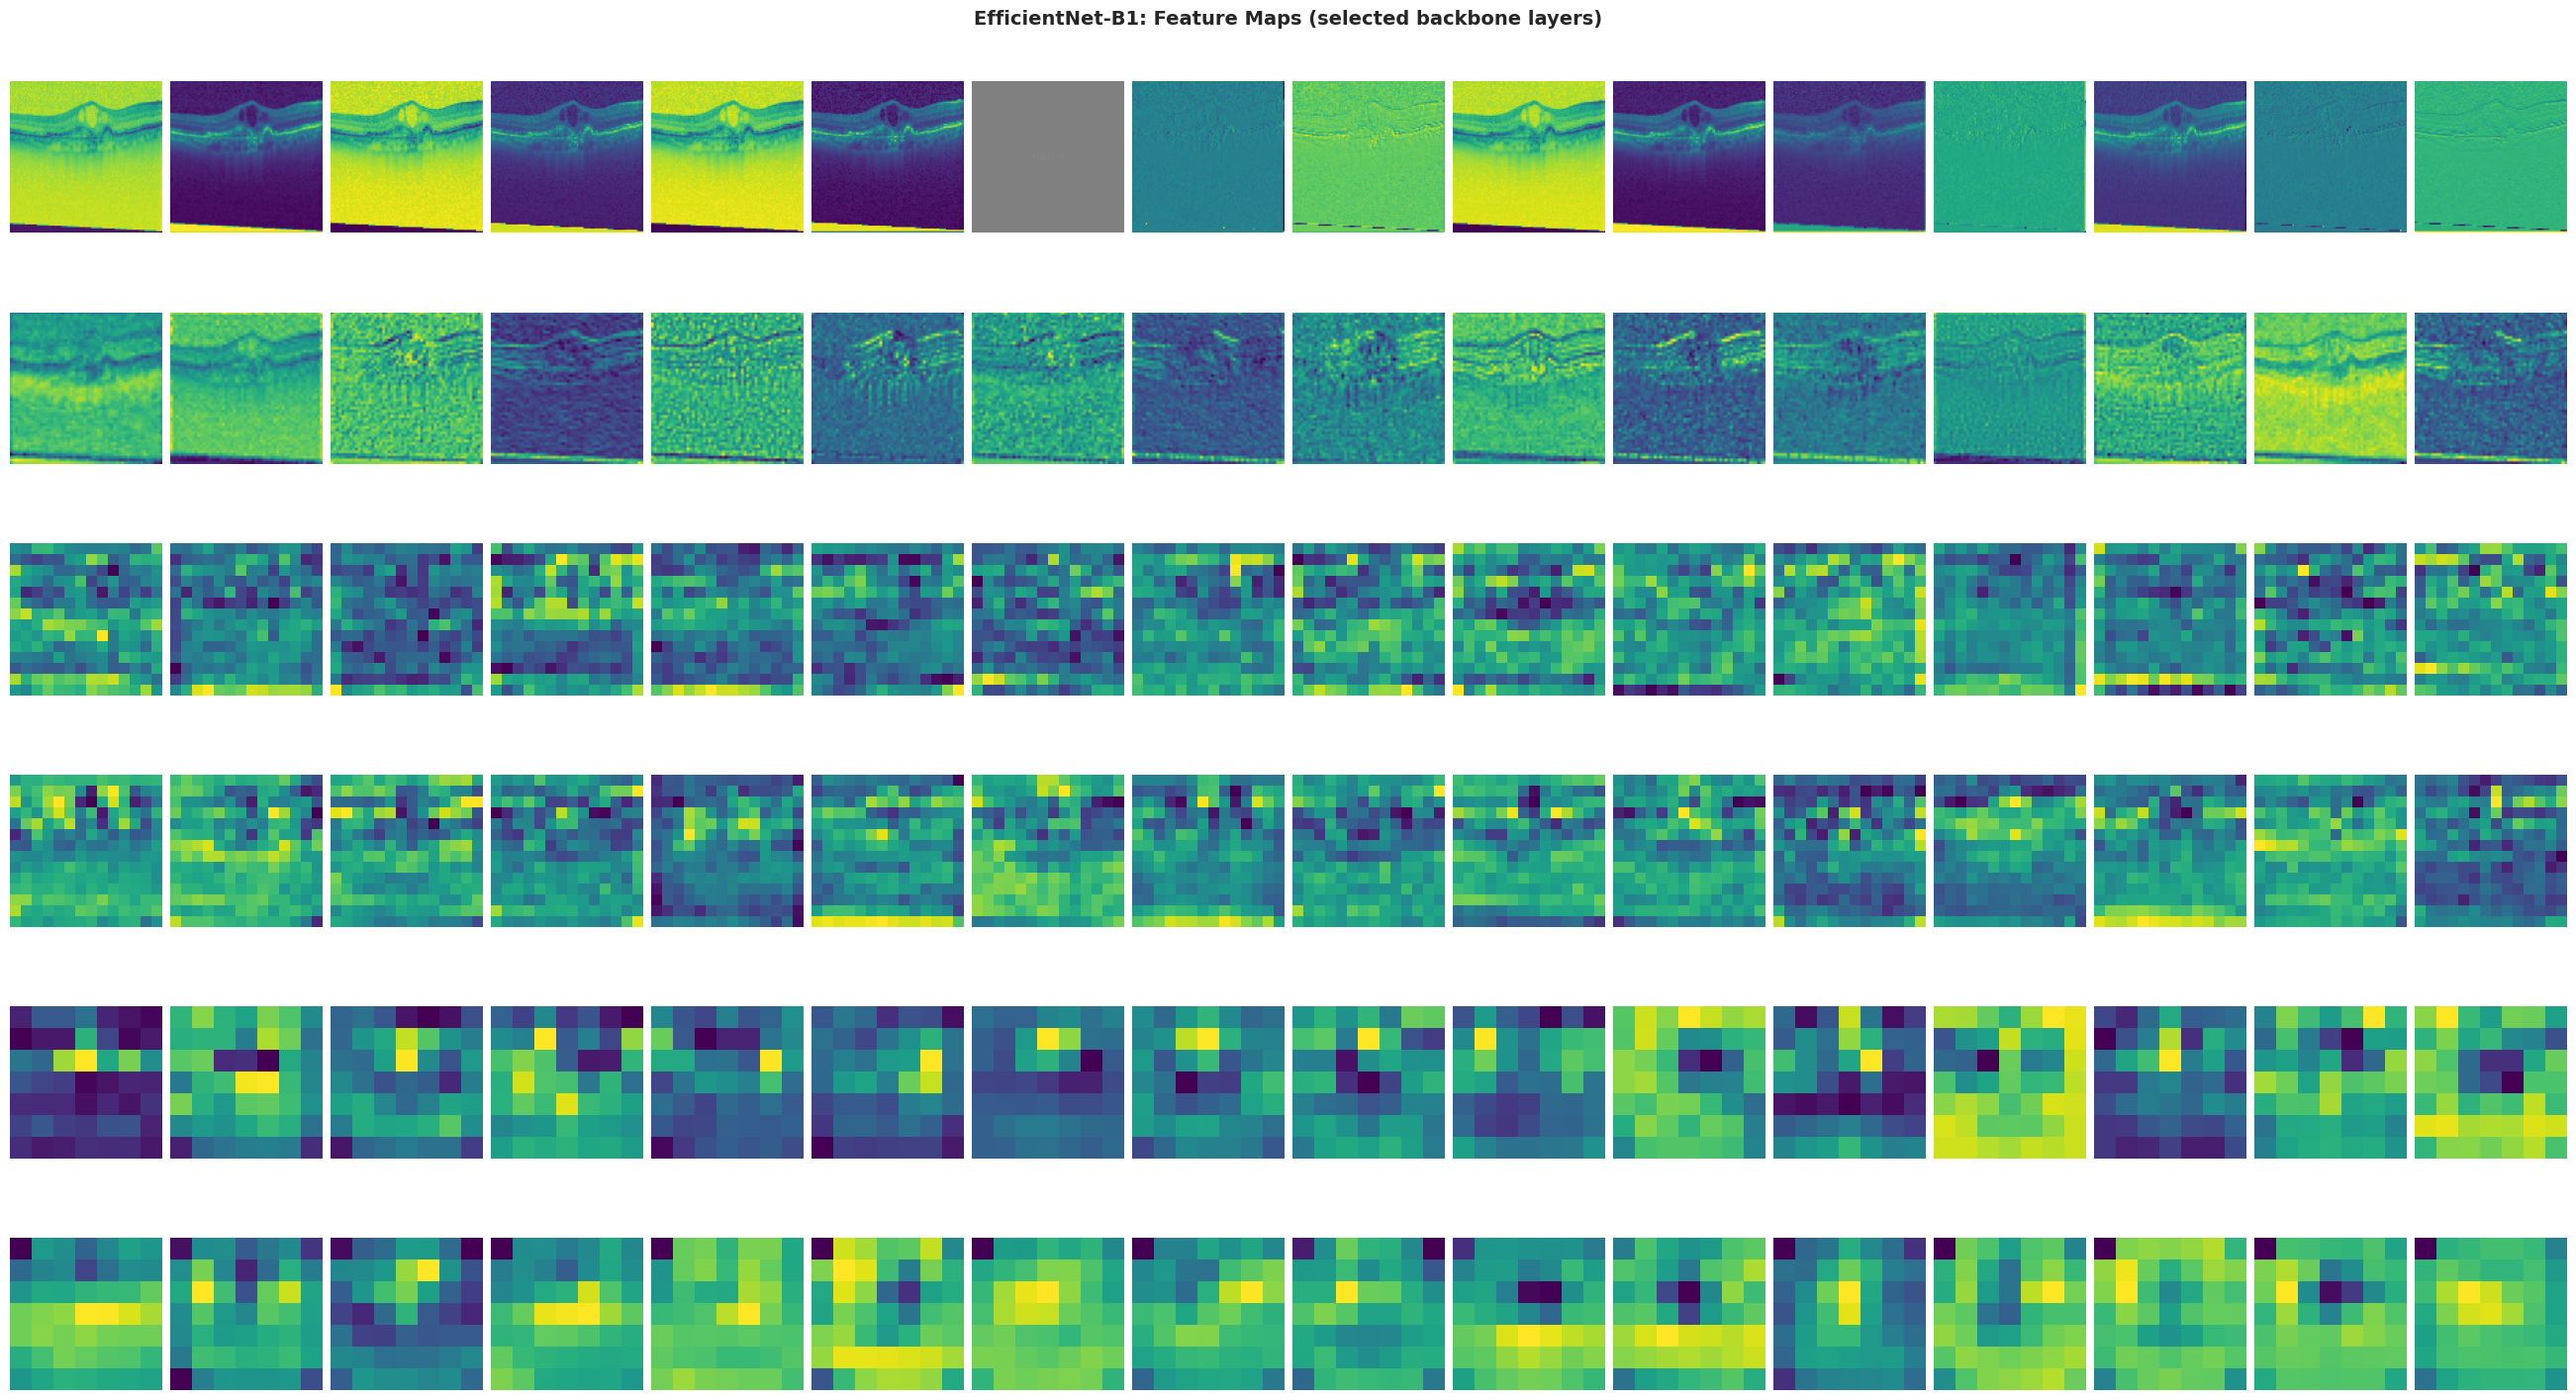

Feature map visualization complete.


In [10]:
test_image = test_images[0]
features, conv_layers = visualize_feature_maps_efficientnet(model, test_image, max_layers=6)


def plot_feature_maps_grid(features, conv_layers, title="Feature Maps", max_filters=16):
    """
    Plot feature maps in a grid (one row per selected layer).

    Dead filters (std < 1e-4 after normalisation) are shown as a grey tile
    with an "inactive" label so the grid stays informative.
    """
    DEAD_THRESH = 1e-4   # filters whose std is below this are considered dead

    total_layers = len(features)
    n_cols = min(max_filters, max(feat.shape[-1] for feat in features))

    fig, axes = plt.subplots(total_layers, n_cols,
                             figsize=(26, 2.5 * total_layers))
    if total_layers == 1:
        axes = axes[np.newaxis, :]

    fig.suptitle(title, fontsize=14, fontweight="bold")

    for layer_idx, (feat, layer) in enumerate(zip(features, conv_layers)):
        num_filters  = feat.shape[-1]
        n_show       = min(max_filters, num_filters)
        dead_count   = 0

        for fi in range(n_cols):
            ax = axes[layer_idx, fi]
            ax.axis("off")

            if fi >= n_show:
                continue

            fmap = feat[0, :, :, fi].astype(np.float32)
            fstd = fmap.std()

            if fstd < DEAD_THRESH:
                # Dead / silent filter - show a grey placeholder
                dead_count += 1
                ax.imshow(
                    np.full(fmap.shape, 0.5),
                    cmap="gray", vmin=0, vmax=1
                )
                ax.text(
                    0.5, 0.5, "inactive",
                    ha="center", va="center",
                    fontsize=6, color="#888888",
                    transform=ax.transAxes,
                )
            else:
                fmin, fmax = fmap.min(), fmap.max()
                fmap = (fmap - fmin) / (fmax - fmin + 1e-8)
                ax.imshow(fmap, cmap="viridis")

            if fi == 0:
                dead_label = f"  ({dead_count} inactive)" if dead_count else ""
                ax.set_ylabel(
                    f"{layer.name}\n({num_filters} filters){dead_label}",
                    fontsize=7, fontweight="bold",
                )

        # Update ylabel with final dead count after iterating all filters
        if dead_count > 0:
            axes[layer_idx, 0].set_ylabel(
                f"{layer.name}\n({num_filters} filters)  [{dead_count} inactive]",
                fontsize=7, fontweight="bold",
            )

    plt.tight_layout(pad=0.5, h_pad=0.4)
    return fig


fig = plot_feature_maps_grid(
    features, conv_layers,
    title="EfficientNet-B1: Feature Maps (selected backbone layers)",
    max_filters=16,
)
plt.savefig(OUTPUT_DIR / "feature_maps_efficientnet.png", dpi=300, bbox_inches="tight")
plt.show()
print("Feature map visualization complete.")


## Feature Space Analysis: t-SNE Visualization

Visualize how the model separates classes in the learned feature space.

In [11]:
# - Full test-set predictions (needed for metrics and t-SNE colouring) -
print("Running full test-set inference...")
y_pred_proba = model.predict(test_set, verbose=1)          # (N, 4)
y_pred       = np.argmax(y_pred_proba, axis=1)             # (N,)

y_true = np.argmax(
    np.concatenate([labels.numpy() for _, labels in test_set], axis=0),
    axis=1,
)                                                           # (N,)

print(f"Test samples: {len(y_true)}")
is_correct = y_pred == y_true
print(f"Overall accuracy: {np.mean(is_correct):.4f}")

Running full test-set inference...
1367/1367 ━━━━━━━━━━━━━━━━━━━━ 82s 42ms/step
Test samples: 10933
Overall accuracy: 0.9695


ADVANCED METRICS SUMMARY (Test Set)
Balanced Accuracy:               0.9554
Matthews Correlation Coefficient:0.9528
Cohen's Kappa:                   0.9527
  CNV     : Sensitivity=0.9693  Specificity=0.9936  Precision=0.9875  F1=0.9783
  DME     : Sensitivity=0.9621  Specificity=0.9925  Precision=0.9387  F1=0.9502
  DRUSEN  : Sensitivity=0.9087  Specificity=0.9858  Precision=0.8493  F1=0.8780
  NORMAL  : Sensitivity=0.9817  Specificity=0.9876  Precision=0.9859  F1=0.9838

AUC Scores (One-vs-Rest):
  CNV: 0.99793
  DME: 0.99698
  DRUSEN: 0.98857
  NORMAL: 0.99800
Macro-average AUC: 0.99537

              precision    recall  f1-score   support

         CNV       0.99      0.97      0.98      3746
         DME       0.94      0.96      0.95      1161
      DRUSEN       0.85      0.91      0.88       887
      NORMAL       0.99      0.98      0.98      5139

    accuracy                           0.97     10933
   macro avg       0.94      0.96      0.95     10933
weighted avg       0.97

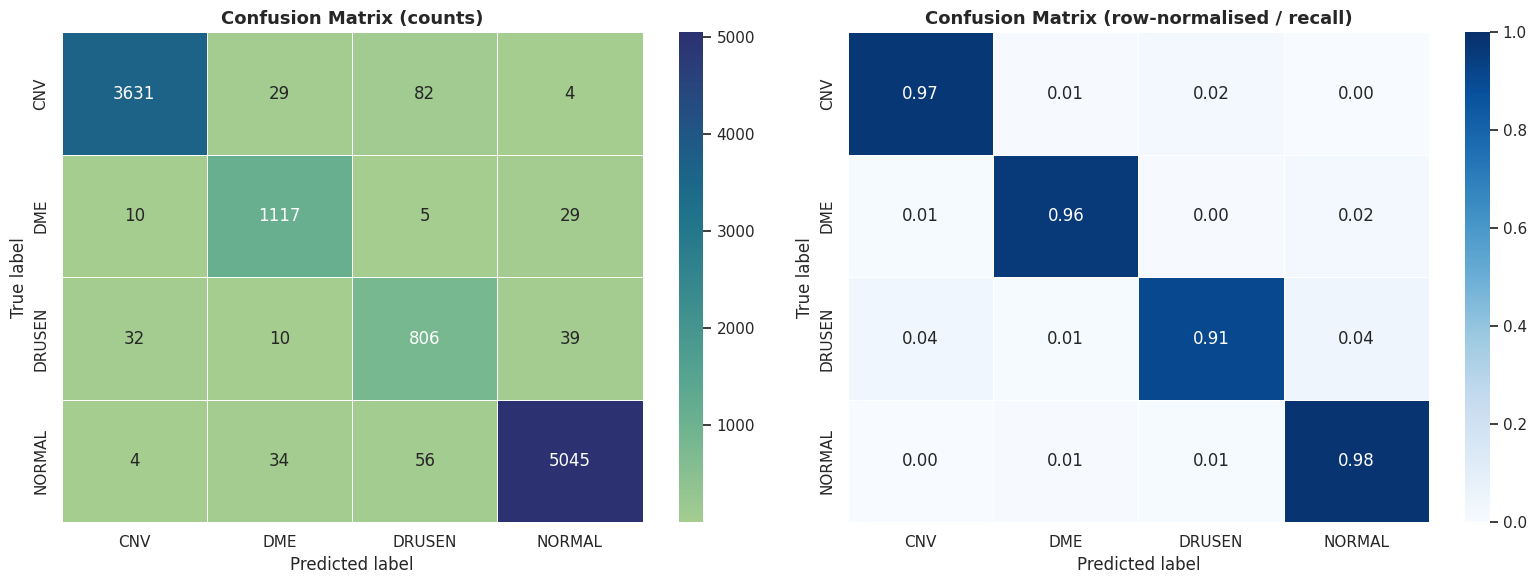

In [12]:
# - Advanced scalar metrics -
balanced_acc = balanced_accuracy_score(y_true, y_pred)
matthews_cc  = matthews_corrcoef(y_true, y_pred)
cohens_kappa = cohen_kappa_score(y_true, y_pred)

print("=" * 60)
print("ADVANCED METRICS SUMMARY (Test Set)")
print("=" * 60)
print(f"Balanced Accuracy:               {balanced_acc:.4f}")
print(f"Matthews Correlation Coefficient:{matthews_cc:.4f}")
print(f"Cohen's Kappa:                   {cohens_kappa:.4f}")

# - Per-class sensitivity / specificity / precision -
cm = confusion_matrix(y_true, y_pred)
metrics_rows = []
for i, class_name in enumerate(class_names):
    tp = cm[i, i]
    fn = cm[i, :].sum() - tp
    fp = cm[:, i].sum() - tp
    tn = cm.sum() - tp - fn - fp
    sens = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    spec = tn / (tn + fp) if (tn + fp) > 0 else 0.0
    prec = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    f1   = 2*prec*sens / (prec + sens) if (prec + sens) > 0 else 0.0
    metrics_rows.append({
        "Class": class_name, "Sensitivity": sens,
        "Specificity": spec, "Precision": prec, "F1": f1,
    })
    print(f"  {class_name:8s}: Sensitivity={sens:.4f}  Specificity={spec:.4f}  Precision={prec:.4f}  F1={f1:.4f}")

metrics_df = pd.DataFrame(metrics_rows)
metrics_df.to_csv(OUTPUT_DIR / "advanced_metrics_per_class.csv", index=False)

# - AUC (one-vs-rest) -
try:
    auc_scores = roc_auc_score(y_true, y_pred_proba, multi_class="ovr", average=None)
    macro_auc  = np.mean(auc_scores)
    print(f"\nAUC Scores (One-vs-Rest):")
    for class_name, auc_score in zip(class_names, auc_scores):
        print(f"  {class_name}: {auc_score:.5f}")
    print(f"Macro-average AUC: {macro_auc:.5f}")
except Exception as e:
    print(f"AUC computation skipped: {e}")

# - Classification report -
print()
print(classification_report(y_true, y_pred, target_names=class_names))

# - Confusion matrix -
cm_df = pd.DataFrame(cm, index=class_names, columns=class_names)
cm_df.to_csv(OUTPUT_DIR / "confusion_matrix.csv")

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.heatmap(cm_df, annot=True, fmt="d", cmap="crest",
            linewidths=0.5, ax=axes[0])
axes[0].set_title("Confusion Matrix (counts)", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Predicted label")
axes[0].set_ylabel("True label")

# Row-normalised confusion matrix (recall per class)
cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)
cm_norm_df = pd.DataFrame(cm_norm, index=class_names, columns=class_names)
sns.heatmap(cm_norm_df, annot=True, fmt=".2f", cmap="Blues",
            linewidths=0.5, ax=axes[1], vmin=0, vmax=1)
axes[1].set_title("Confusion Matrix (row-normalised / recall)", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Predicted label")
axes[1].set_ylabel("True label")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()



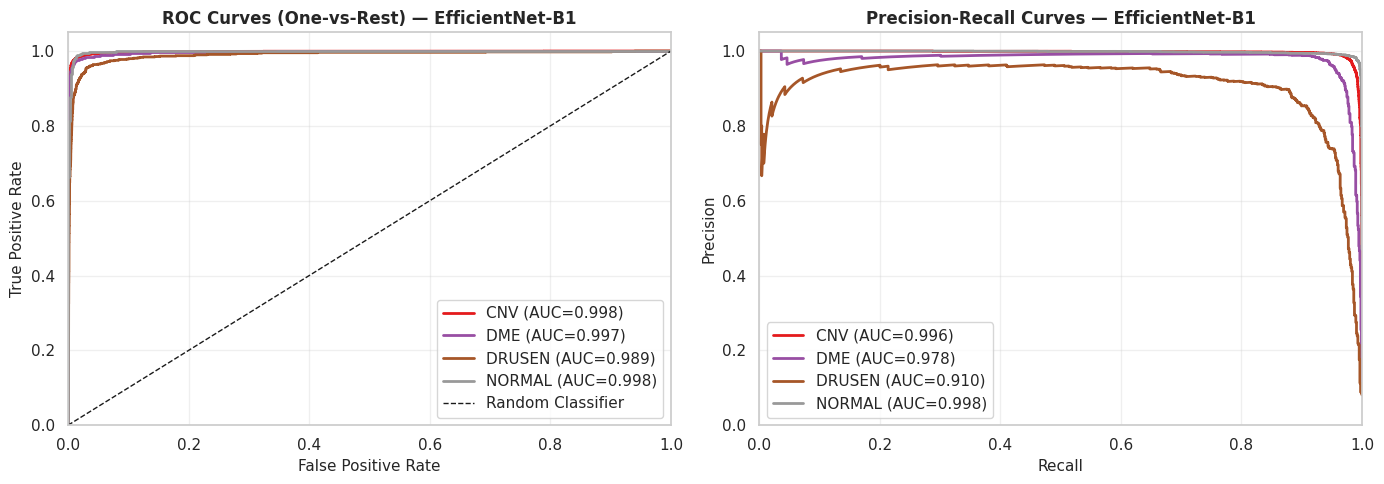

In [13]:
# - ROC and Precision-Recall curves (One-vs-Rest) -
y_true_bin = label_binarize(y_true, classes=range(num_classes))
colors = plt.cm.Set1(np.linspace(0, 1, num_classes))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for i, class_name in enumerate(class_names):
    fpr, tpr, _ = roc_curve(y_true_bin[:, i], y_pred_proba[:, i])
    roc_auc = auc(fpr, tpr)
    axes[0].plot(fpr, tpr, color=colors[i], lw=2, label=f"{class_name} (AUC={roc_auc:.3f})")

axes[0].plot([0, 1], [0, 1], "k--", lw=1, label="Random Classifier")
axes[0].set_xlim([0.0, 1.0]); axes[0].set_ylim([0.0, 1.05])
axes[0].set_xlabel("False Positive Rate", fontsize=11)
axes[0].set_ylabel("True Positive Rate", fontsize=11)
axes[0].set_title("ROC Curves (One-vs-Rest) — EfficientNet-B1", fontsize=12, fontweight="bold")
axes[0].legend(loc="lower right")
axes[0].grid(alpha=0.3)

for i, class_name in enumerate(class_names):
    precision, recall, _ = precision_recall_curve(y_true_bin[:, i], y_pred_proba[:, i])
    pr_auc = auc(recall, precision)
    axes[1].plot(recall, precision, color=colors[i], lw=2, label=f"{class_name} (AUC={pr_auc:.3f})")

axes[1].set_xlim([0.0, 1.0]); axes[1].set_ylim([0.0, 1.05])
axes[1].set_xlabel("Recall", fontsize=11)
axes[1].set_ylabel("Precision", fontsize=11)
axes[1].set_title("Precision-Recall Curves — EfficientNet-B1", fontsize=12, fontweight="bold")
axes[1].legend(loc="best")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "roc_and_pr_curves_efficientnet.png", dpi=300, bbox_inches="tight")
plt.show()

Feature extractor output shape: (None, 1280)
Extracting bottleneck features from full test set...
Extracted 10933 vectors of dim 1280
Applying t-SNE (this may take a moment)...
[t-SNE] Computing 91 nearest neighbors...
[t-SNE] Indexed 10933 samples in 0.006s...
[t-SNE] Computed neighbors for 10933 samples in 10.421s...
[t-SNE] Computed conditional probabilities for sample 1000 / 10933
[t-SNE] Computed conditional probabilities for sample 2000 / 10933
[t-SNE] Computed conditional probabilities for sample 3000 / 10933
[t-SNE] Computed conditional probabilities for sample 4000 / 10933
[t-SNE] Computed conditional probabilities for sample 5000 / 10933
[t-SNE] Computed conditional probabilities for sample 6000 / 10933
[t-SNE] Computed conditional probabilities for sample 7000 / 10933
[t-SNE] Computed conditional probabilities for sample 8000 / 10933
[t-SNE] Computed conditional probabilities for sample 9000 / 10933
[t-SNE] Computed conditional probabilities for sample 10000 / 10933
[t-SNE] 

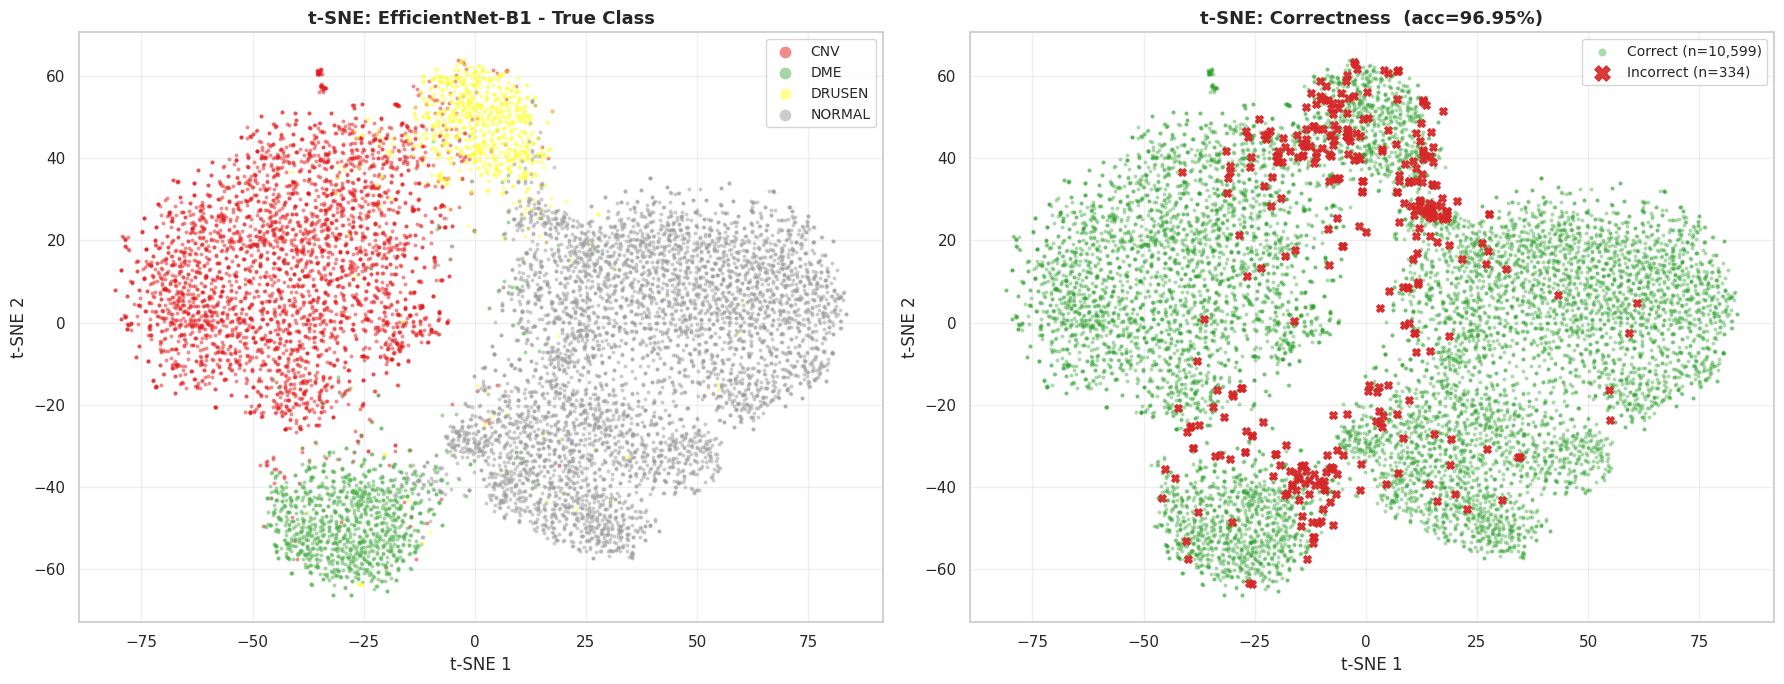

t-SNE visualization complete.


In [14]:
# ---------------------------------------------------------------------------
# Build a feature extractor that outputs the 1792-D GAP embedding.
# EfficientNetB1 backbone is a functional model, so backbone.input/.output
# are valid. We wire: grayscale input -> Concatenate -> preprocess ->
# backbone -> GlobalAveragePooling2D.
# ---------------------------------------------------------------------------

backbone = _get_backbone(model)

backbone_model = tf.keras.Model(
    inputs=backbone.input,
    outputs=backbone.output,
    name="backbone_for_tsne",
)

inp_t   = tf.keras.Input(shape=IMG_SIZE + (NUM_CHANNELS,), name="tsne_in")
x_rgb_t = Concatenate(axis=-1)([inp_t, inp_t, inp_t])
x_prep_t = tf.keras.layers.Lambda(
    tf.keras.applications.efficientnet.preprocess_input,
    name="preprocess_tsne",
)(x_rgb_t)
bb_out_t  = backbone_model(x_prep_t)
gap_out_t = GlobalAveragePooling2D()(bb_out_t)

feature_extractor = tf.keras.Model(
    inputs=inp_t,
    outputs=gap_out_t,
    name="efficientnet_feature_extractor",
)
print(f"Feature extractor output shape: {feature_extractor.output_shape}")

print("Extracting bottleneck features from full test set...")
test_features_list, test_labels_list = [], []
for images, labels in test_set:
    feats = feature_extractor(images, training=False)
    test_features_list.append(feats.numpy())
    test_labels_list.append(np.argmax(labels.numpy(), axis=1))

test_features      = np.concatenate(test_features_list, axis=0).astype(np.float32)
test_labels_actual = np.concatenate(test_labels_list,   axis=0)
print(f"Extracted {test_features.shape[0]} vectors of dim {test_features.shape[1]}")

# - t-SNE -
print("Applying t-SNE (this may take a moment)...")
from sklearn.manifold import TSNE
tsne = TSNE(n_components=2, random_state=SEED, perplexity=30, max_iter=1000, verbose=1)
features_tsne = tsne.fit_transform(test_features)   # (N, 2)

# - Plot -
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

palette = plt.cm.Set1(np.linspace(0, 0.9, num_classes))
for i, cname in enumerate(class_names):
    mask = test_labels_actual == i
    axes[0].scatter(
        features_tsne[mask, 0], features_tsne[mask, 1],
        color=palette[i], label=cname, alpha=0.5, s=8, linewidths=0,
    )
axes[0].set_title("t-SNE: EfficientNet-B1 - True Class", fontsize=13, fontweight="bold")
axes[0].set_xlabel("t-SNE 1"); axes[0].set_ylabel("t-SNE 2")
axes[0].legend(markerscale=3, fontsize=10); axes[0].grid(alpha=0.3)

axes[1].scatter(
    features_tsne[is_correct, 0], features_tsne[is_correct, 1],
    color="#2ca02c", label=f"Correct (n={is_correct.sum():,})",
    alpha=0.4, s=8, linewidths=0,
)
axes[1].scatter(
    features_tsne[~is_correct, 0], features_tsne[~is_correct, 1],
    color="#d62728", label=f"Incorrect (n={(~is_correct).sum():,})",
    alpha=0.9, s=30, marker="X",
)
overall_acc = np.mean(is_correct)
axes[1].set_title(f"t-SNE: Correctness  (acc={overall_acc:.2%})",
                  fontsize=13, fontweight="bold")
axes[1].set_xlabel("t-SNE 1"); axes[1].set_ylabel("t-SNE 2")
axes[1].legend(markerscale=2, fontsize=10); axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "feature_space_tsne_efficientnet.png", dpi=300, bbox_inches="tight")
plt.show()
print("t-SNE visualization complete.")


## Confidence Triangle Plots: Cₙₑₜ, Cᵇᵉˢᵗ, Cₜᵣᵘᵉ

Three scatter plots showing the relationship between the model’s confidence scores:
- **(a)** Cₜᵣᵘᵉ vs Cₛᵉᶜᵒⁿᵈᴸᵉₛᵗ - how confident the model is in the true class vs. the runner-up
- **(b)** Cᵇᵉˢᵗ vs Cₛᵉᶜᵒⁿᵈᴸᵉₛᵗ - top prediction confidence vs. runner-up
- **(c)** Cᵇᵉˢᵗ vs Cₜᵣᵘᵉ - separates correct (diagonal) from incorrect (off-diagonal) predictions


In [15]:
# - Triangle plot helper ---------------------------
def triangle_plot(x, y, xlabel, ylabel, panel, ax):
    """
    Scatter plot confined to the probability simplex triangle.
    Adapted for EfficientNet: accepts an Axes object for subplot layout.
    """
    ax.scatter(x, y, s=15, alpha=0.75, color="#4a627a")

    # Triangle boundaries
    ax.plot([0, 1], [0, 0], linestyle="--", color="#888", linewidth=1)   # bottom
    t = np.linspace(0, 1, 200)
    ax.plot(t, 1 - t, linestyle="--", color="#888", linewidth=1)          # hypotenuse
    ax.plot([0, 1], [0, 1], linestyle="--", color="#e07070", linewidth=1) # diagonal ref

    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_xlabel(xlabel, fontsize=12)
    ax.set_ylabel(ylabel, fontsize=12)
    ax.text(0.03, 0.94, panel, fontsize=14, fontweight="bold",
            transform=ax.transAxes)
    ax.set_aspect("equal")
    ax.grid(True, alpha=0.3)


In [16]:
# - prepData: compute C_best / C_second / C_true and draw triangle plots --─
def prepData(dataset, split_name="Dataset"):
    """
    Runs inference on `dataset`, extracts C_best, C_second, C_true,
    prints top-1/top-2 accuracy, and saves the triangle figure.

    Uses the session-level `class_names` and `num_classes` variables
    instead of dataset.class_names, which is lost after .prefetch().
    """
    # class_names and num_classes are defined at the top of the notebook
    # (loaded from stage1_meta.json and confirmed by load_dataset)
    print(f"\n{'='*60}")
    print(f"TRIANGLE PLOT  -  {split_name}  ({num_classes} classes)")
    print("="*60)

    # - Predictions -
    y_prob = model.predict(dataset, verbose=1)          # (N, num_classes)
    y_true = np.concatenate(
        [y.numpy() for _, y in dataset], axis=0
    )                                                   # (N, num_classes) one-hot
    y_true_idx = np.argmax(y_true, axis=1)              # (N,)

    top1_idx  = np.argmax(y_prob, axis=1)
    top2_pred = np.argsort(y_prob, axis=1)[:, -2:]     # top-2 indices per sample

    top1_correct = (y_true_idx == top1_idx)
    top2_accuracy = np.mean([
        y_true_idx[i] in top2_pred[i] for i in range(len(y_true_idx))
    ])

    print(f"Top-1 Accuracy : {np.mean(top1_correct):.4f}")
    print(f"Top-2 Accuracy : {top2_accuracy:.4f}")

    # - Confidence scores -
    sorted_probs = np.sort(y_prob, axis=1)
    C_best   = np.max(y_prob, axis=1)
    C_second = sorted_probs[:, -2]
    C_true   = y_prob[np.arange(len(y_true_idx)), y_true_idx]

    print(f"C_true > C_best (should be False): {np.any(C_true > C_best + 1e-6)}")
    print(f"Probs sum to 1 : {np.allclose(np.sum(y_prob, axis=1), 1, atol=1e-3)}")

    # - Plot -
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    fig.suptitle(
        f"Confidence Triangle Plots  -  {split_name}",
        fontsize=15, fontweight="bold", y=1.02
    )

    triangle_plot(C_true,  C_second, r"$C_{True}$",  r"$C_{SecondBest}$", "a", axes[0])
    triangle_plot(C_best,  C_second, r"$C_{Best}$",  r"$C_{SecondBest}$", "b", axes[1])
    triangle_plot(C_best,  C_true,   r"$C_{Best}$",  r"$C_{True}$",       "c", axes[2])

    plt.tight_layout()
    fname = OUTPUT_DIR / f"triangle_plot_{split_name.lower().replace(' ', '_')}.png"
    plt.savefig(fname, dpi=300, bbox_inches="tight")
    plt.show()
    print(f"Saved: {fname}")

    return C_best, C_second, C_true, top1_correct



TRIANGLE PLOT  -  Test Set  (4 classes)
1367/1367 ━━━━━━━━━━━━━━━━━━━━ 31s 23ms/step
Top-1 Accuracy : 0.9695
Top-2 Accuracy : 0.9962
C_true > C_best (should be False): False
Probs sum to 1 : True


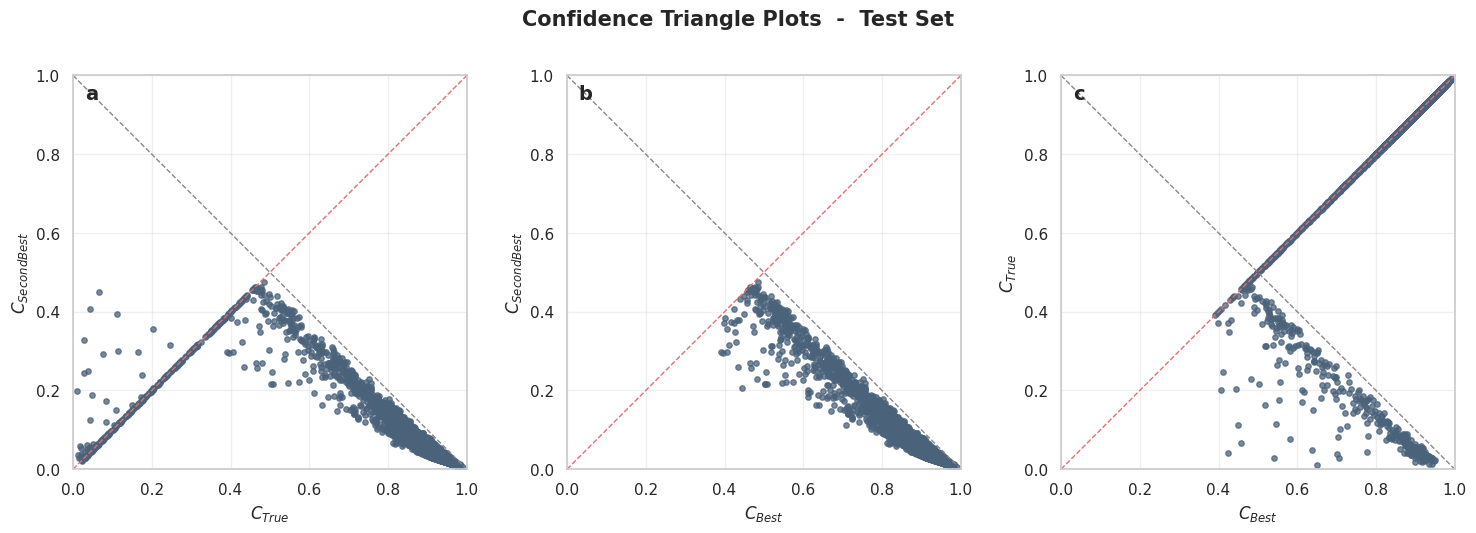

Saved: /content/drive/MyDrive/oct_outputs_featureViz_efficientnet_b1/triangle_plot_test_set.png

TRIANGLE PLOT  -  Validation Set  (4 classes)
2733/2733 ━━━━━━━━━━━━━━━━━━━━ 73s 27ms/step
Top-1 Accuracy : 0.9690
Top-2 Accuracy : 0.9966
C_true > C_best (should be False): False
Probs sum to 1 : True


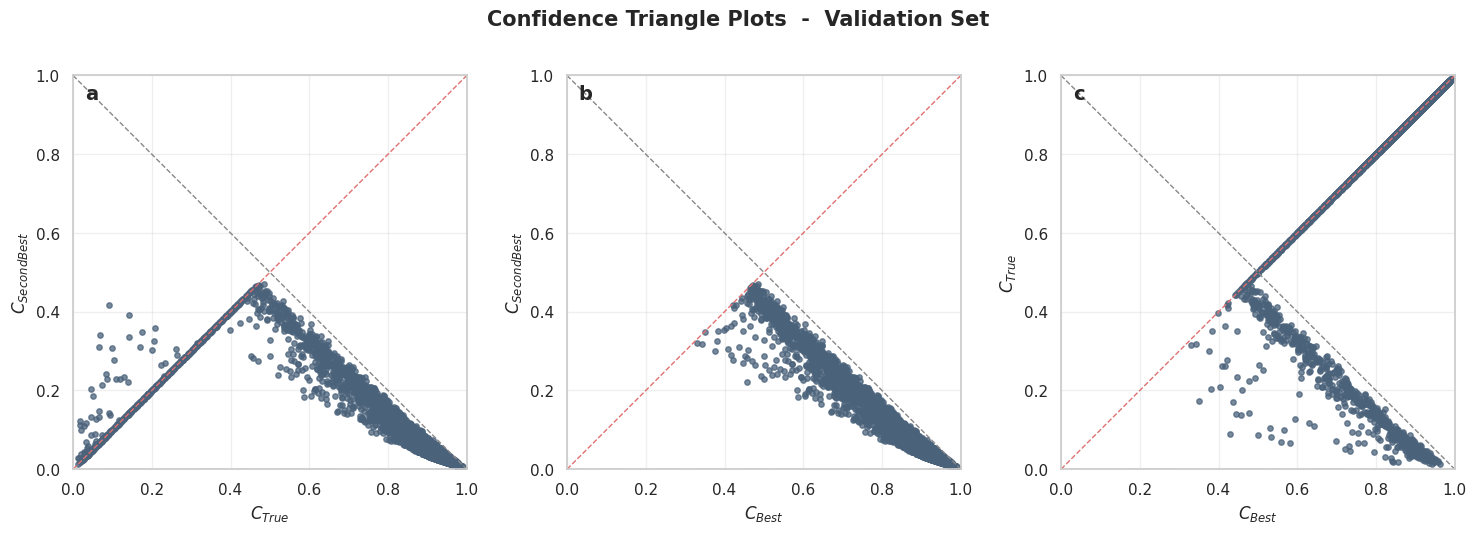

Saved: /content/drive/MyDrive/oct_outputs_featureViz_efficientnet_b1/triangle_plot_validation_set.png

TRIANGLE PLOT  -  Training Set  (4 classes)
9565/9565 ━━━━━━━━━━━━━━━━━━━━ 294s 31ms/step
Top-1 Accuracy : 0.3585
Top-2 Accuracy : 0.5275
C_true > C_best (should be False): False
Probs sum to 1 : True


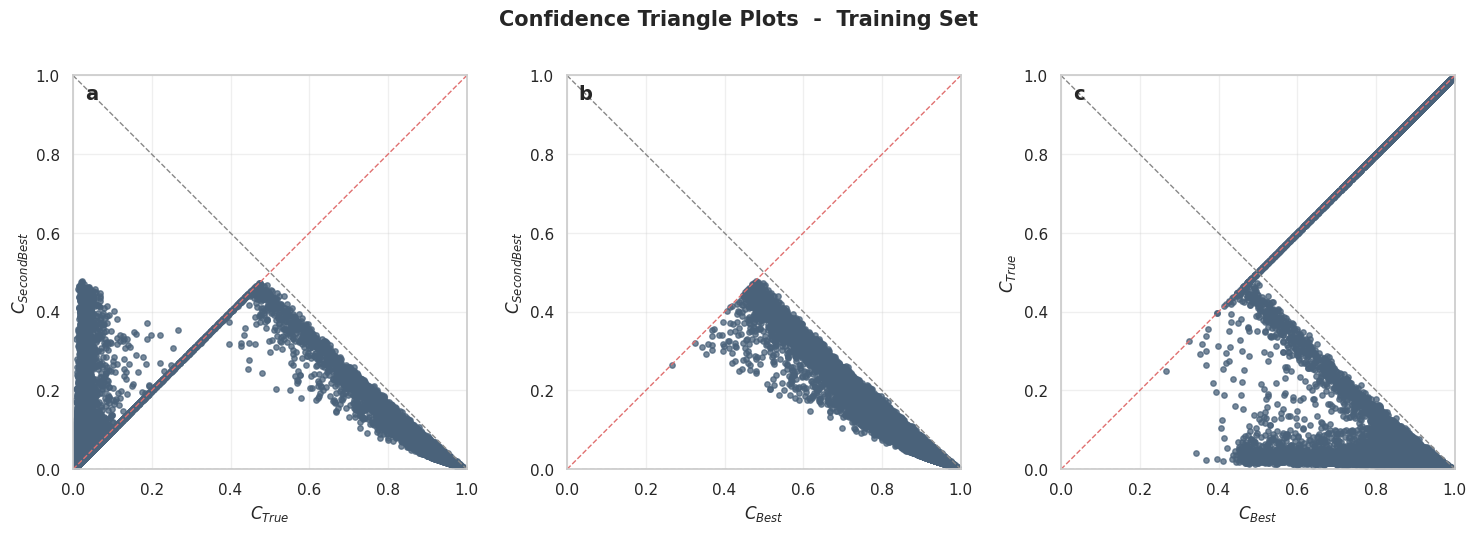

Saved: /content/drive/MyDrive/oct_outputs_featureViz_efficientnet_b1/triangle_plot_training_set.png


In [17]:
# - Run triangle plots for test, validation, and training sets --------
C_best_test, C_second_test, C_true_test, correct_test = prepData(test_set,       "Test Set")
C_best_val,  C_second_val,  C_true_val,  correct_val  = prepData(validation_set, "Validation Set")
C_best_train,C_second_train,C_true_train,correct_train= prepData(training_set,   "Training Set")


## Radar Plot: Per-Class Classification Metrics

Precision, Recall, and F1-score for each disease class visualised on a
polar (spider) chart. Metrics are computed directly from the test-set
predictions already generated above - no external CSV needed.


In [18]:
# - Radar plot helpers ----------------------------
def plot_all_metrics_combined(labels, angles, metrics):
    """All three metrics on one polar chart with premium styling."""
    fig = plt.figure(figsize=(12, 12), facecolor="#f8faff")
    ax  = plt.subplot(111, polar=True)
    ax.set_facecolor("#fdfdff")

    colors  = ["#4a627a", "#50a18f", "#ff8c7a"]   # Deep Blue, Teal, Coral
    markers = ["o", "s", "^"]

    for (title, values), color, marker in zip(metrics.items(), colors, markers):
        vals = values + values[:1]
        ax.plot(angles, vals, linewidth=3, linestyle="-", label=title,
                color=color, marker=marker, markersize=8,
                markerfacecolor="white", markeredgewidth=2)
        ax.fill(angles, vals, color=color, alpha=0.08)

    ax.set_thetagrids(
        np.degrees(angles[:-1]), labels,
        fontsize=11, fontweight="bold", color="#333333"
    )
    ax.set_ylim(0, 1)
    ax.grid(True, linestyle="--", alpha=0.6, color="#cbd5e0")

    plt.suptitle("Model Evaluation: Classification Metrics",
                 size=26, weight="bold", color="#1a365d", y=0.98)
    ax.set_title("Per-class performance - EfficientNet-B1",
                 size=15, style="italic", color="#4a627a", pad=40)

    legend = ax.legend(loc="upper right", bbox_to_anchor=(1.3, 1.1),
                       frameon=True, shadow=True, fontsize=12)
    legend.get_frame().set_facecolor("white")
    legend.get_frame().set_edgecolor("#1a365d")

    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    fname = OUTPUT_DIR / "radar_plot_efficientnet.png"
    plt.savefig(fname, dpi=300, bbox_inches="tight")
    plt.show()
    print(f"Saved: {fname}")


def plot_metrics_separately(labels, angles, metrics):
    """One polar chart per metric."""
    colors  = {"Precision": "#4a627a", "Recall": "#50a18f", "F1-score": "#ff8c7a"}
    markers = {"Precision": "o",       "Recall": "s",       "F1-score": "^"}

    for title, values in metrics.items():
        vals = values + values[:1]
        fig  = plt.figure(figsize=(9, 9), facecolor="#f8faff")
        ax   = plt.subplot(111, polar=True)
        ax.set_facecolor("#fdfdff")

        color  = colors.get(title, "#4a627a")
        marker = markers.get(title, "o")

        ax.plot(angles, vals, linewidth=3, linestyle="-", label=title,
                color=color, marker=marker, markersize=8,
                markerfacecolor="white", markeredgewidth=2)
        ax.fill(angles, vals, color=color, alpha=0.15)

        ax.set_thetagrids(
            np.degrees(angles[:-1]), labels,
            fontsize=11, fontweight="bold", color="#333333"
        )
        ax.set_ylim(0, 1)
        ax.grid(True, linestyle="--", alpha=0.6, color="#cbd5e0")
        ax.set_title(f"Class-wise {title}", size=22, weight="bold",
                     color="#1a365d", y=1.1, pad=30)

        legend = ax.legend(loc="upper right", bbox_to_anchor=(1.25, 1.1),
                           frameon=True, shadow=True)
        legend.get_frame().set_facecolor("white")
        legend.get_frame().set_edgecolor("#1a365d")

        plt.tight_layout()
        plt.show()


Per-class metrics:
        precision    recall  f1-score  support
CNV      0.987490  0.969301  0.978311   3746.0
DME      0.938655  0.962102  0.950234   1161.0
DRUSEN   0.849315  0.908681  0.877996    887.0
NORMAL   0.985929  0.981709  0.983814   5139.0

Generating combined radar plot...


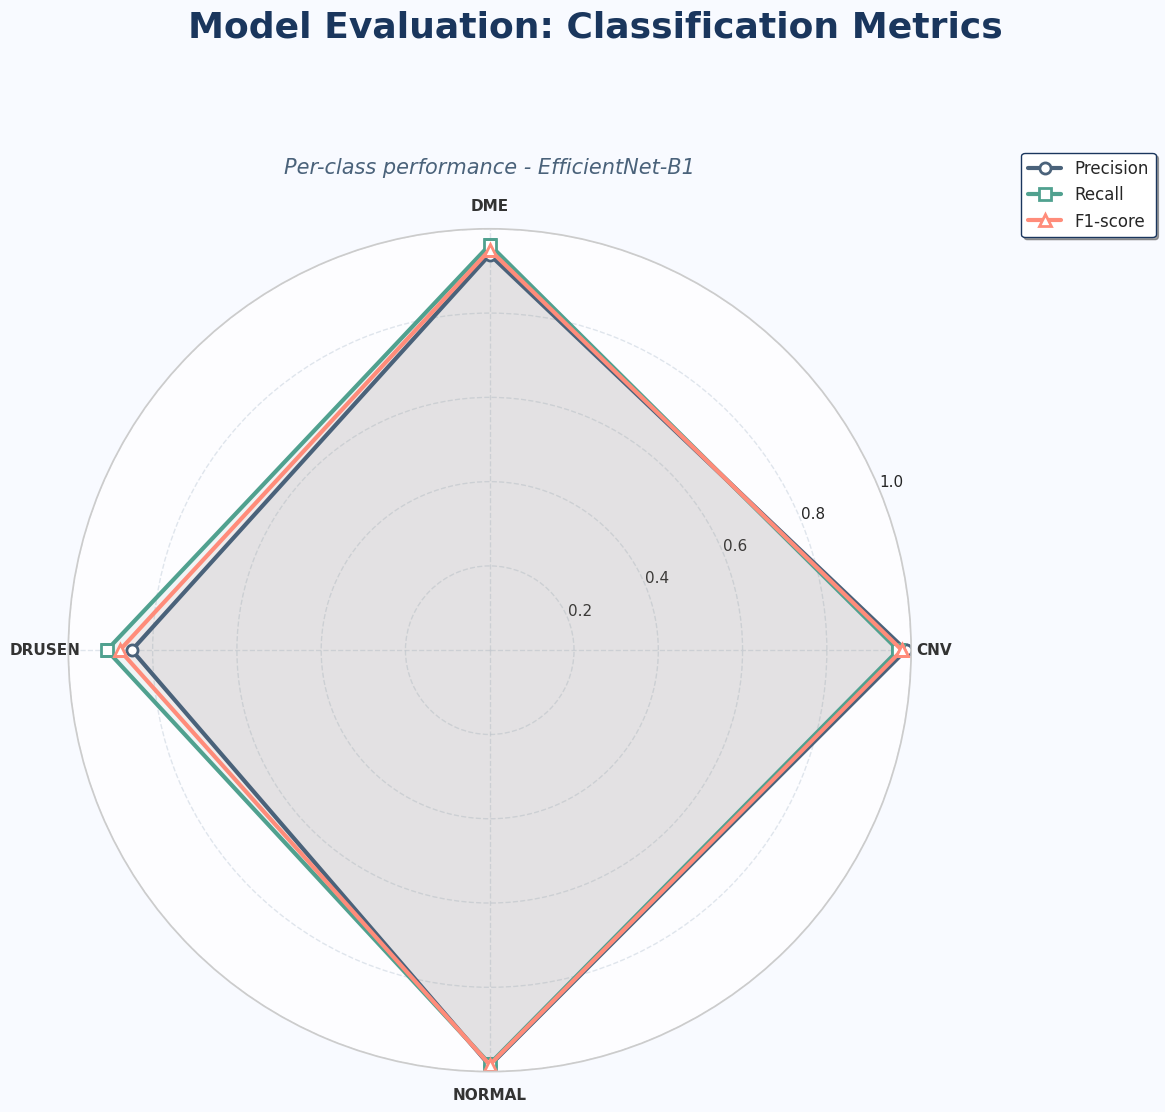

Saved: /content/drive/MyDrive/oct_outputs_featureViz_efficientnet_b1/radar_plot_efficientnet.png

Generating individual radar plots...


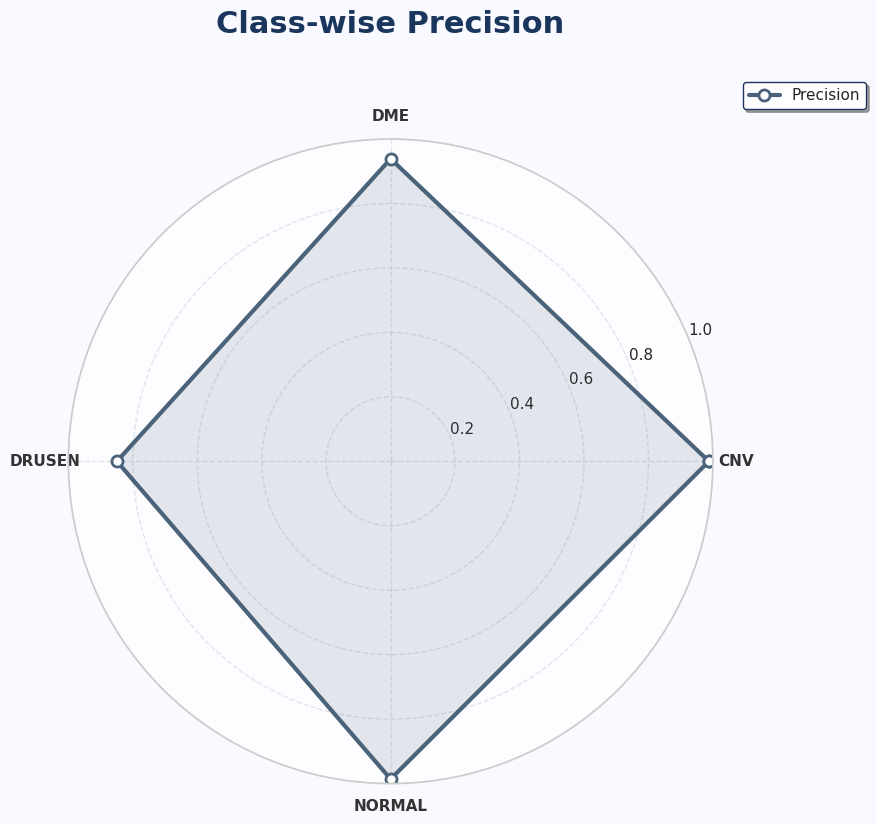

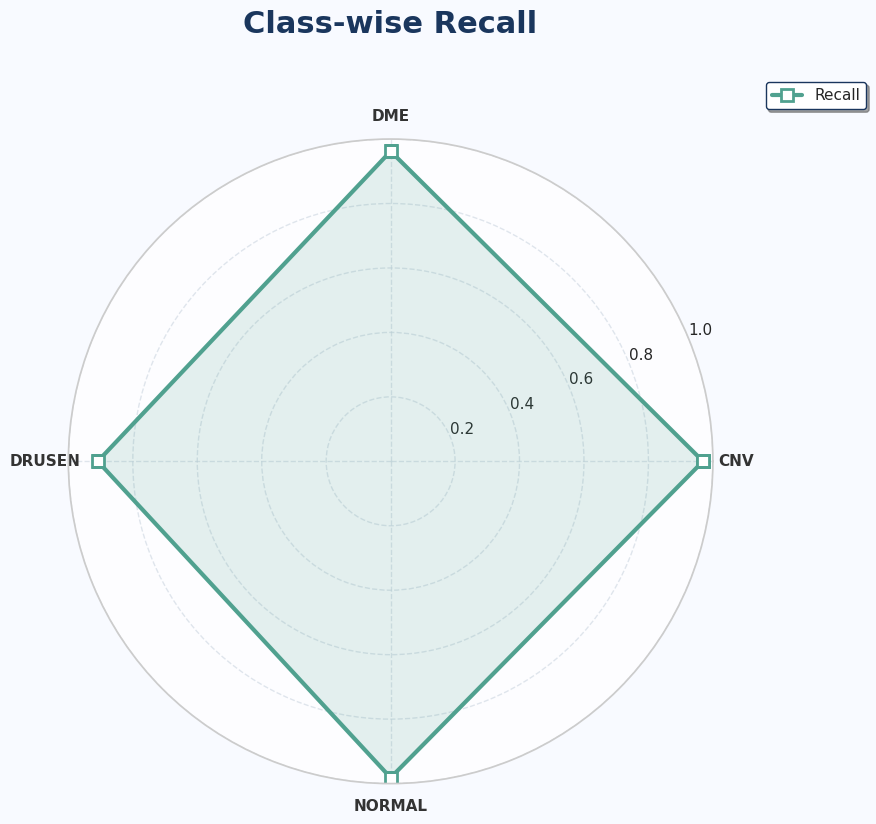

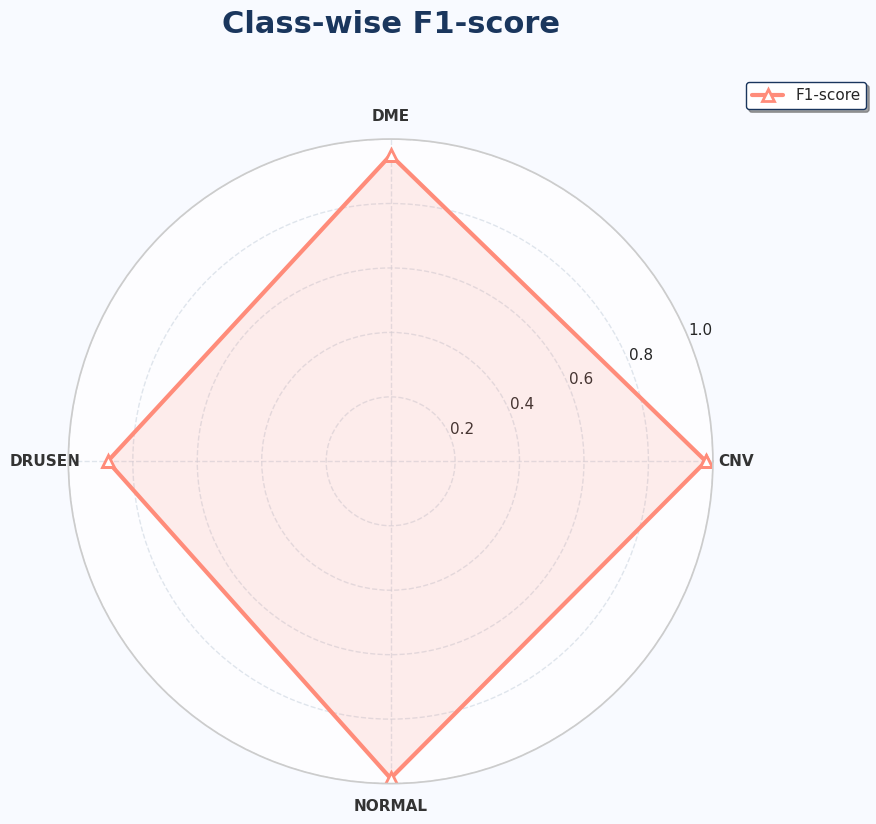

In [19]:
# - Build metrics from live test-set predictions (y_true / y_pred from above) ─
# Requires cell 16 (full test-set inference) to have been run first.
from sklearn.metrics import classification_report
import pandas as pd

report_dict = classification_report(
    y_true, y_pred,
    target_names=class_names,
    output_dict=True,
    zero_division=0,
)

# Keep only the per-class rows (drop accuracy / avg rows)
skip = {"accuracy", "macro avg", "weighted avg"}
radar_labels  = [k for k in report_dict if k not in skip]
radar_metrics = {
    "Precision": [report_dict[c]["precision"] for c in radar_labels],
    "Recall"   : [report_dict[c]["recall"]    for c in radar_labels],
    "F1-score" : [report_dict[c]["f1-score"]  for c in radar_labels],
}

# Save classification report as CSV for reference
report_df = pd.DataFrame(report_dict).T
report_df.to_csv(OUTPUT_DIR / "classification_report_efficientnet.csv")
print("Per-class metrics:")
print(report_df.loc[radar_labels])

# Build angles for radar plot
angles = np.linspace(0, 2 * np.pi, len(radar_labels), endpoint=False).tolist()
angles += angles[:1]

print("\nGenerating combined radar plot...")
plot_all_metrics_combined(radar_labels, angles, radar_metrics)

print("\nGenerating individual radar plots...")
plot_metrics_separately(radar_labels, angles, radar_metrics)


## Summary: Interpretability Report

In [20]:
summary_report = (
    "# OCT Eye Disease - EfficientNet-B1 Interpretability Report\n\n"
    f"Generated: {pd.Timestamp.now()}\n\n"
    "### Model\n"
    "- Architecture : EfficientNet-B1 (ImageNet pretrained, grayscale -> RGB)\n"
    f"- Grad-CAM target layer (inside backbone): {grad_cam.target_layer}\n\n"
    "### Results\n"
    f"- Test samples  : {test_features.shape[0]} x {test_features.shape[1]}-D GAP embeddings\n"
    f"- Overall acc   : {overall_acc:.2%}\n"
    f"- Balanced acc  : {balanced_acc:.4f}\n"
    f"- Matthews CC   : {matthews_cc:.4f}\n"
    f"- Cohen Kappa   : {cohens_kappa:.4f}\n"
    f"- Correct       : {is_correct.sum():,} / {len(is_correct):,}\n"
    f"- Misclassified : {(~is_correct).sum():,}\n\n"
    "### Per-class Metrics\n"
    + metrics_df.to_string(index=False)
    + "\n\n### Output Files\n"
    "  gradcam_correct_predictions.png\n"
    "  gradcam_incorrect_predictions.png\n"
    "  feature_maps_efficientnet.png\n"
    "  feature_space_tsne_efficientnet.png\n"
    "  confusion_matrix.png / .csv\n"
    "  advanced_metrics_per_class.csv\n"
    "  interpretability_report_efficientnet.txt\n"
)

with open(OUTPUT_DIR / "interpretability_report_efficientnet.txt", "w") as f:
    f.write(summary_report)

print(summary_report)
print(f"Report saved to {OUTPUT_DIR / 'interpretability_report_efficientnet.txt'}")


# OCT Eye Disease - EfficientNet-B1 Interpretability Report

Generated: 2026-07-14 20:59:37.846960

### Model
- Architecture : EfficientNet-B1 (ImageNet pretrained, grayscale -> RGB)
- Grad-CAM target layer (inside backbone): top_conv

### Results
- Test samples  : 10933 x 1280-D GAP embeddings
- Overall acc   : 96.95%
- Balanced acc  : 0.9554
- Matthews CC   : 0.9528
- Cohen Kappa   : 0.9527
- Correct       : 10,599 / 10,933
- Misclassified : 334

### Per-class Metrics
 Class  Sensitivity  Specificity  Precision       F1
   CNV     0.969301     0.993600   0.987490 0.978311
   DME     0.962102     0.992530   0.938655 0.950234
DRUSEN     0.908681     0.985765   0.849315 0.877996
NORMAL     0.981709     0.987573   0.985929 0.983814

### Output Files
  gradcam_correct_predictions.png
  gradcam_incorrect_predictions.png
  feature_maps_efficientnet.png
  feature_space_tsne_efficientnet.png
  confusion_matrix.png / .csv
  advanced_metrics_per_class.csv
  interpretability_report_efficientnet.

## Clinical Validation Guidance

### For Ophthalmology Review:

1. **Grad-CAM Analysis**
   - Compare heatmaps with clinical knowledge of each disease:
     - **CNV (Choroidal Neovascularization)**: Should highlight abnormal vascular growth
     - **DME (Diabetic Macular Edema)**: Should highlight fluid accumulation in macula
     - **DRUSEN**: Should highlight yellowish deposits
     - **NORMAL**: Should highlight normal retinal structure

2. **Feature Space Clustering**
   - Inspect misclassified samples (red X markers)
   - Are they clinically ambiguous cases?
   - Are they borderline between two diseases?

3. **Confidence Assessment**
   - Low-confidence predictions may require expert review
   - High-confidence predictions increase trust in automation

In [21]:
print("EfficientNet-B1 Feature Visualization Complete!")
print(f"All outputs saved to: {OUTPUT_DIR}")


EfficientNet-B1 Feature Visualization Complete!
All outputs saved to: /content/drive/MyDrive/oct_outputs_featureViz_efficientnet_b1
